In [ ]:
%load_ext autoreload
%autoreload 2

### Figure 6: Assay-specific biases are adopted by PepCL and FT.

 - __a)__ EpiScan R9/RT models cysteine and hydrophobicity enrichment.
 - __b)__ EpiScan R9/RT models P8 enrichment and V9/VL trade-off.
 - __d)__ YD ΔEntropy and JSD between FT and PepCL. 
 - __e)__ YD ΔEntropy and JSD between FT and PepCL at PΩ. 
 - __f)__ Sequence logo plots for A0301, A3001, and A1101. 

In [ ]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT.name not in ("CLSBN26", "PepCL_Manuscript"):
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError("Could not find CLSBN26 project root.")
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "Data"
SRC_DIR = PROJECT_ROOT / "src"
FIGURES_DIR = PROJECT_ROOT / "Figures"
MODEL_CHECKPOINTS_DIR = PROJECT_ROOT / "Model_Checkpoints"

print("PROJECT_ROOT:", PROJECT_ROOT)
print("PROJECT_ROOT in sys.path:", str(PROJECT_ROOT) in sys.path)

PROJECT_ROOT: /home/pchati/PepCL_Manuscript
PROJECT_ROOT in sys.path: True


In [ ]:
# get mhc pseudosequences
from Data.mhc_pseudo_seqs import mhc_seq_dict
mhc_seq_dict={k.removeprefix("HLA-").replace("*","").replace(":",""):v for k,v in mhc_seq_dict.items()}

# get utils
from src.general_utils import *

# get feature data and processed feature table
from src.get_feature_data import *

# plotting fns
from src.plotting import *

# misc
import warnings
warnings.filterwarnings("ignore")
device="cuda"

In [ ]:
"""
Set figure output directory
"""
# create central repository and for this figure
central_figure_dir="Figure6"

# associated data dir
associated_data_dir=f"{central_figure_dir}/Associated_Data"

### Fig. 6a: EpiScan R9/RT cysteine and hydrophicitiy enrichment

In [ ]:
# get background set for scoring
# chp_background_for_episcsan_processed=pd.read_csv(f"{DATA_DIR}/chp_background_for_episcsan_processed.csv", index_col=0)

# with validation selected models
chp_background_for_episcsan_processed=pd.read_csv(f"{DATA_DIR}/chp_background_for_episcsan_processed_r9rt_opt.csv", index_col=0)

In [ ]:
%%time
# residue enrichment of cysteines

# score_cols=["mhcprime", "episcan_r9_ft", "episcan_r9_pepcl", "episcan_r9rt_ft", "episcan_r9rt_pepcl"]

score_cols=['mhcprime_abt', 'episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4_seed_3', 'episcan_r9rt_ft_steps_400_lr_2eN4_seed_2', 'episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4_seed_2', 'episcan_r9rt_ft_steps_400_lr_2eN4_seed_4', 'episcan_r9rt_ft_steps_400_lr_2eN4_seed_1', 'episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4_seed_0', 'episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4_seed_1', 'episcan_r9rt_ft_steps_400_lr_2eN4_seed_3', 'episcan_r9rt_ft_steps_400_lr_2eN4_seed_0', 'episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4_seed_4', 'episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4_seed_5', 'episcan_r9rt_ft_steps_400_lr_2eN4_seed_5', 'episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4_seed_6', 'episcan_r9rt_ft_steps_400_lr_2eN4_seed_6', 'episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4_seed_7', 'episcan_r9rt_ft_steps_400_lr_2eN4_seed_7', 'episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4_seed_8', 'episcan_r9rt_ft_steps_400_lr_2eN4_seed_8']


chp_cys_enrich=residue_enrichment_top_n(
    df=chp_background_for_episcsan_processed,
    peptide_col="peptide",
    cluster_col="allele",
    score_cols=score_cols,
    top_n=2000,
    residue = 'C',
    fraction = True,
)

# l2fc_chp_cys_enrich=log2_enrichment_vs_base(chp_cys_enrich, "mhcprime", eps=0.0)
l2fc_chp_cys_enrich=log2_enrichment_vs_base(chp_cys_enrich, "mhcprime_abt", eps=0.0)

CPU times: user 1.75 s, sys: 92.5 ms, total: 1.84 s
Wall time: 1.84 s


In [ ]:
%%time
# compute hydropathy of all sequences and repeat analysis with this (hydrophobicity or more so)
from Bio.SeqUtils.ProtParam import ProteinAnalysis

KD = {
    "I": 4.5, "V": 4.2, "L": 3.8, "F": 2.8, "C": 2.5,
    "M": 1.9, "A": 1.8, "G": -0.4, "T": -0.7, "S": -0.8,
    "W": -0.9, "Y": -1.3, "P": -1.6, "H": -3.2, "E": -3.5,
    "Q": -3.5, "D": -3.5, "N": -3.5, "K": -3.9, "R": -4.5
}

def compute_gravy(seq: str) -> float:
    return sum(KD[aa] for aa in seq) / len(seq)

chp_background_for_episcsan_processed["gravy"]=chp_background_for_episcsan_processed.peptide.apply(compute_gravy)

CPU times: user 426 ms, sys: 16 ms, total: 442 ms
Wall time: 442 ms


In [ ]:
# hydrophobicity enrichment
chp_hydro_enrich=avg_col_top_n(
    df=chp_background_for_episcsan_processed,
    # df=chp_background_for_episcsan_processed_cleaned,
    cluster_col="allele",
    score_cols=score_cols,
    top_n=2000,
    target_col = "gravy",
)

# chp_hydro_enrich_delta_base=delta_vs_base(chp_hydro_enrich, "mhcprime")
chp_hydro_enrich_delta_base=delta_vs_base(chp_hydro_enrich, "mhcprime_abt")

In [ ]:
# cysteine and delta gravy enrichment avg
prefix_map={
    "episcan_r9rt_ft":"episcan_r9rt_ft_steps_400_lr_2eN4",
    "episcan_r9rt_pepcl":"episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4",
}

l2fc_chp_cys_enrich, l2fc_chp_cys_enrich_ci=average_columns_by_prefix_with_ci(
    l2fc_chp_cys_enrich,
    prefix_map,
)

chp_hydro_enrich_delta_base, chp_hydro_enrich_delta_base_ci=average_columns_by_prefix_with_ci(
    chp_hydro_enrich_delta_base,
    prefix_map,
)

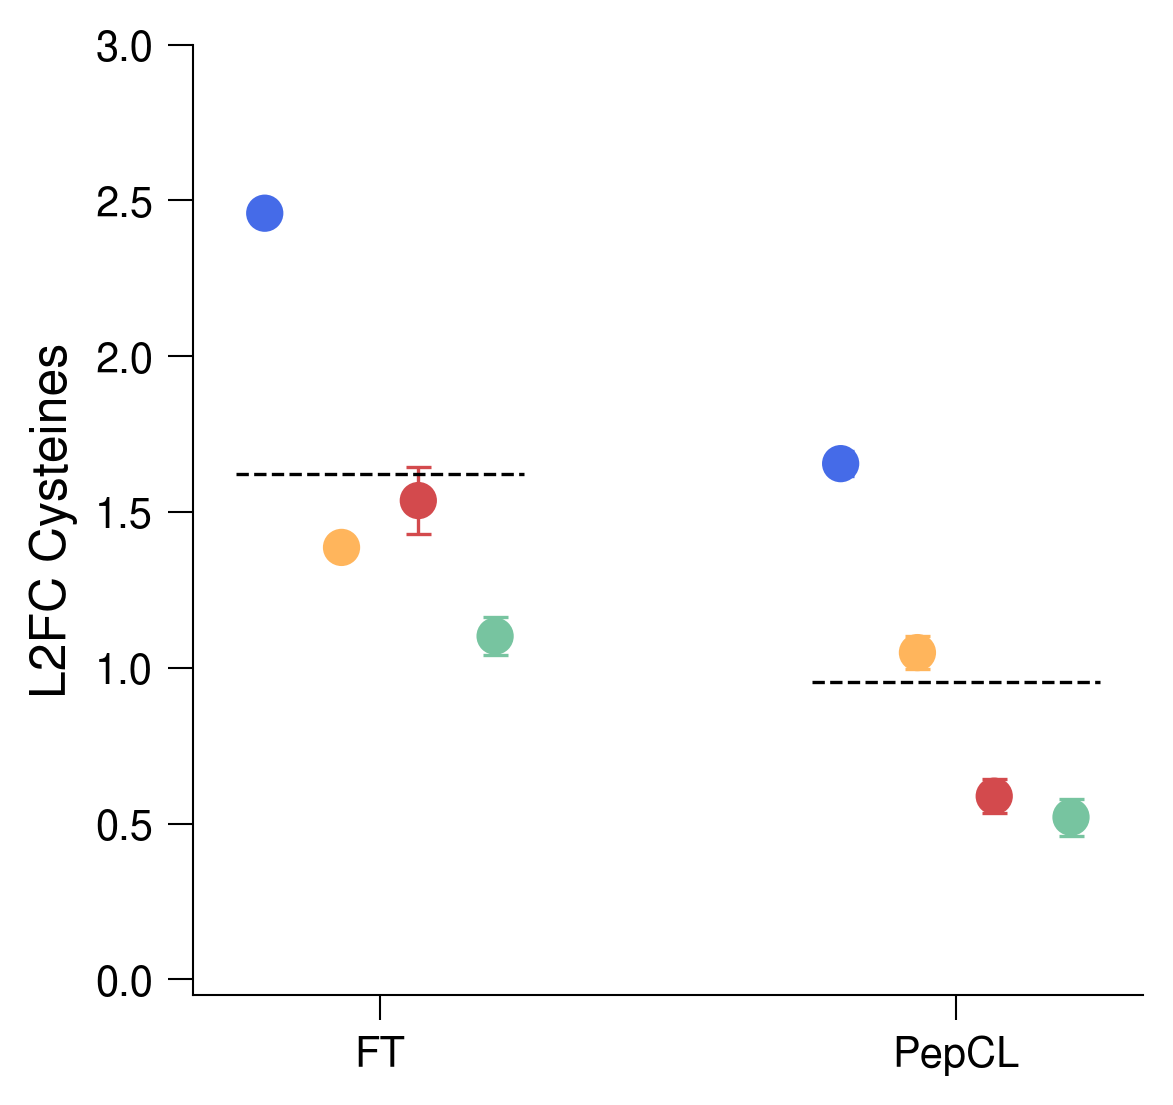

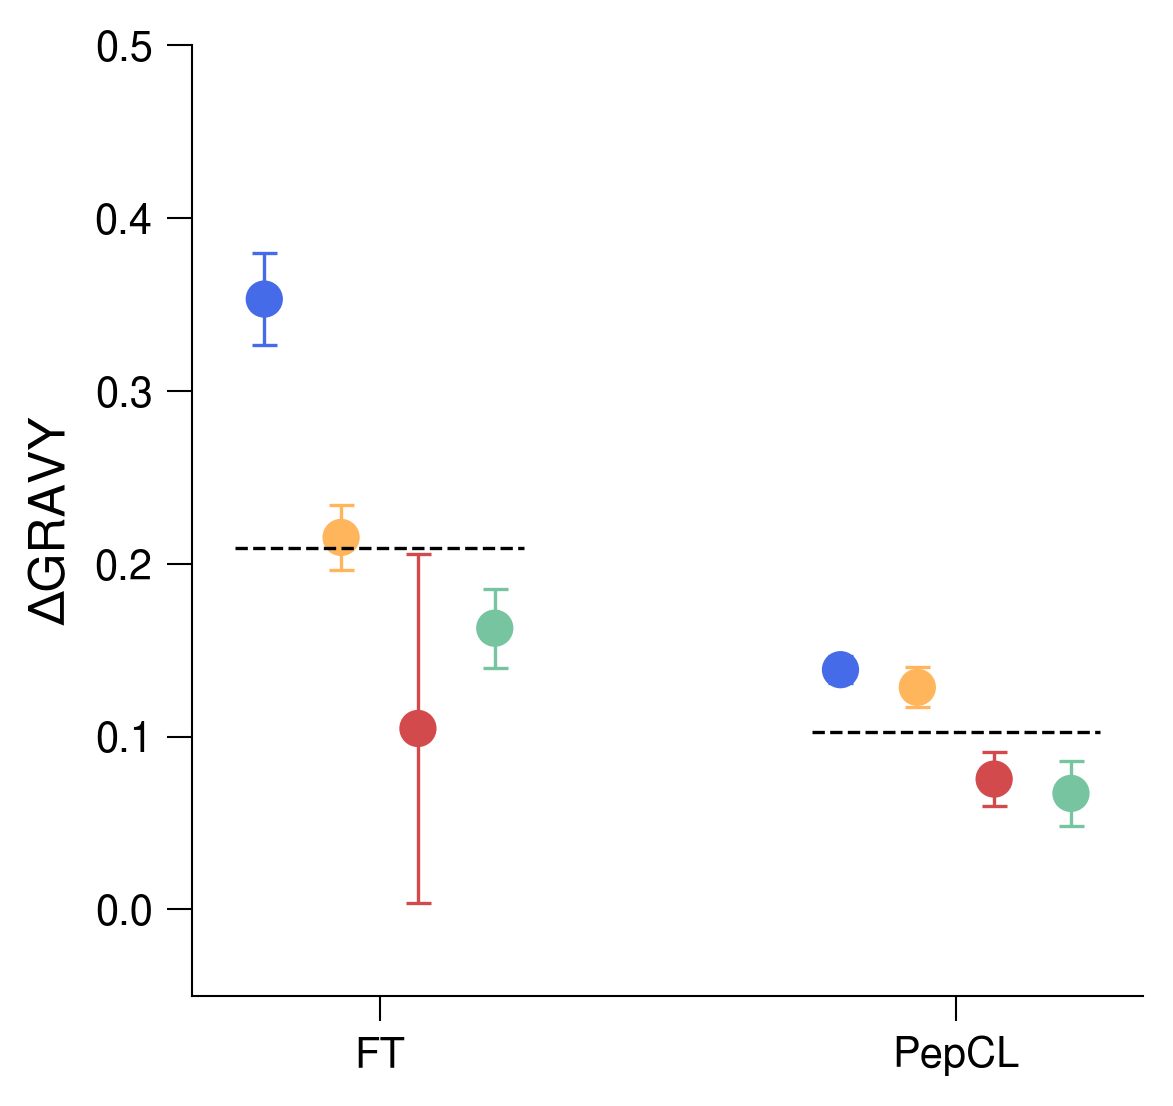

In [ ]:
# jitterplot (labels and titles adjusted in illustrator)
legend_labels_dict = {
    "episcan_r9rt_ft": "FT",
    "episcan_r9rt_pepcl": "PepCL",
}

colors=["#456be8", "#ffb55c", "#D34A4D", "#77C4A0"]
plot_params=dict(
    col_label_dict=legend_labels_dict,
    figsize=(4,4),
    dpi=300,
    default_font='Nimbus Sans',
    jitter=0.4,
    point_size=80,
    # point_size=60,
    # point_size=40,
    point_alpha=1.0,
    point_edge_color='none',
    point_edge_width=0,
    point_marker='o',
    colors=colors,
    show_mean=True,
    mean_above_points=True,
    mean_color='black',
    mean_width=0.8,
    mean_style='--',
    mean_length_pad=0.05,
    # ci_line_width=1.0,
    # ci_color='black',
    # ci_cap_style='line',
    # ci_cap_width=4.0,
    # ci_alpha=1.0,
    title=None,
    title_fontsize=14,
    title_bold=False,
    xlabel=None,
    ylabel=None,
    xlabel_fontsize=12,
    ylabel_fontsize=12,
    xlabel_pad=4.0,
    ylabel_pad=4.0,
    xtick_labelsize=10,
    ytick_labelsize=10,
    xtick_rotation=0,
    xtick_ha='center',
    despine=True,
    spine_width=0.5,
    tick_length=6.0,
    tick_width=0.5,
    tick_direction='out',
    ylim=None,
    grid_alpha=0.0,
    hide_legend=True,
    legend_fontsize=8,
    legend_loc='upper center',
    legend_bbox=(0.5, -0.15),
    legend_ncol=4,
    legend_frameon=False,
    square_aspect=True,
    show=True,
    y_bottom_pad=0.05,
    y_clip_top=True,

    show_ci=True,
    ci_color=None,
    ci_line_width=0.8,
    ci_linestyle="-",
    ci_alpha=1.0,
    ci_show_caps=True,
    ci_cap_size=3.0,
    ci_cap_thickness=0.8,

)

plot_params["ylabel"]="L2FC Cysteines"
plot_params["ylim"]=(0,3.0)
_=plot_jitter_advanced_v3(
    l2fc_chp_cys_enrich, 
    ci_df=l2fc_chp_cys_enrich_ci,
    # save_path=f"{central_figure_dir}/fig6_a_episcan_rtr9_models_cl_log2_cysteine_enrichment_jitter_plot_across_seeds",
    **plot_params,
)

plot_params["ylabel"]="ΔGRAVY"
plot_params["ylim"]=(0.0, 0.5)
_=plot_jitter_advanced_v3(
    chp_hydro_enrich_delta_base,
    ci_df=chp_hydro_enrich_delta_base_ci,
    # save_path=f"{central_figure_dir}/fig6_a_episcan_rtr9_models_cl_gravy_hydrophobicity_change_delta_jitter_plot_across_seeds",
    **plot_params,
)

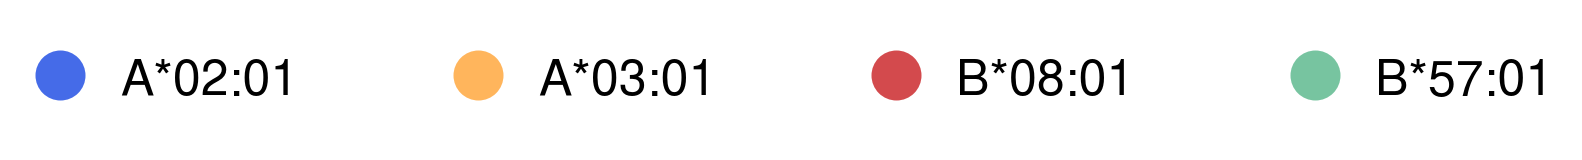

In [ ]:
# legend resized and formatted in illustrator
plot_horizontal_legend(
    legend_dict={
        'A*02:01': '#456be8',
        'A*03:01': '#ffb55c',
        'B*08:01':'#D34A4D',
        'B*57:01':'#77C4A0',
    },
    swatch_size=12,
    text_size=12,
    item_spacing=30,
    swatch_text_gap=6,
    swatch_outline_color='black',
    swatch_outline_width=0.8,
    figsize=None,
    dpi=300,
    default_font='Nimbus Sans',
    swatch_shape="circle",
    # save_path=f"{central_figure_dir}/fig6_a_legend",

)

In [ ]:
"""
Save dataframes associated with figures.
"""
save_dfs=False
# save_dfs=True

if save_dfs:
    l2fc_chp_cys_enrich.to_csv(f"{associated_data_dir}/l2fc_chp_cys_enrich.csv")
    chp_hydro_enrich_delta_base.to_csv(f"{associated_data_dir}/chp_hydro_enrich_delta_base.csv")
    l2fc_chp_cys_enrich_ci.to_csv(f"{associated_data_dir}/l2fc_chp_cys_enrich_ci.csv")
    chp_hydro_enrich_delta_base_ci.to_csv(f"{associated_data_dir}/chp_hydro_enrich_delta_base_ci.csv")

### Fig. 6b: EpiScan R9/RT P8 enrichment and VL/V9 trade-off

In [ ]:
# P8 enrichment
score_cols=['mhcprime_abt', 'episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4_seed_3', 'episcan_r9rt_ft_steps_400_lr_2eN4_seed_2', 'episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4_seed_2', 'episcan_r9rt_ft_steps_400_lr_2eN4_seed_4', 'episcan_r9rt_ft_steps_400_lr_2eN4_seed_1', 'episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4_seed_0', 'episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4_seed_1', 'episcan_r9rt_ft_steps_400_lr_2eN4_seed_3', 'episcan_r9rt_ft_steps_400_lr_2eN4_seed_0', 'episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4_seed_4', 'episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4_seed_5', 'episcan_r9rt_ft_steps_400_lr_2eN4_seed_5', 'episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4_seed_6', 'episcan_r9rt_ft_steps_400_lr_2eN4_seed_6', 'episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4_seed_7', 'episcan_r9rt_ft_steps_400_lr_2eN4_seed_7', 'episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4_seed_8', 'episcan_r9rt_ft_steps_400_lr_2eN4_seed_8', 'episcan_r9rt_log_odds']

chp_P8_enrich=residue_enrichment_top_n(
    df=chp_background_for_episcsan_processed,
    peptide_col="peptide",
    cluster_col="allele",
    score_cols=score_cols,
    top_n=2000,
    residue = 'P',
    fraction = True,
    position = 8,
)

In [ ]:
# process p8 enrichment df
score_cols_no_base=['episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4_seed_3', 'episcan_r9rt_ft_steps_400_lr_2eN4_seed_2', 'episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4_seed_2', 'episcan_r9rt_ft_steps_400_lr_2eN4_seed_4', 'episcan_r9rt_ft_steps_400_lr_2eN4_seed_1', 'episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4_seed_0', 'episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4_seed_1', 'episcan_r9rt_ft_steps_400_lr_2eN4_seed_3', 'episcan_r9rt_ft_steps_400_lr_2eN4_seed_0', 'episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4_seed_4', 'episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4_seed_5', 'episcan_r9rt_ft_steps_400_lr_2eN4_seed_5', 'episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4_seed_6', 'episcan_r9rt_ft_steps_400_lr_2eN4_seed_6', 'episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4_seed_7', 'episcan_r9rt_ft_steps_400_lr_2eN4_seed_7', 'episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4_seed_8', 'episcan_r9rt_ft_steps_400_lr_2eN4_seed_8', 'episcan_r9rt_log_odds']


# create merged df
# chp_l2fc_p8_enrich=log2_enrichment_vs_base(chp_P8_enrich, "mhcprime", eps=0.0)
chp_l2fc_p8_enrich=log2_enrichment_vs_base(chp_P8_enrich, "mhcprime_abt", eps=0.0)

# merge for a0201
chp_l2fc_p8_enrich_a0201=chp_l2fc_p8_enrich.loc[["A0201"]].T.loc[score_cols_no_base]
chp_l2fc_p8_enrich_a0201.index=[c+"_a0201" for c in chp_l2fc_p8_enrich_a0201.index]
chp_l2fc_p8_enrich_a0201.reset_index(inplace=True)
chp_l2fc_p8_enrich_a0201.columns=["model_name", "p8_enrich"]

# for b0801
chp_l2fc_p8_enrich_b0801=chp_l2fc_p8_enrich.loc[["B0801"]].T.loc[score_cols_no_base]
chp_l2fc_p8_enrich_b0801.index=[c+"_b0801" for c in chp_l2fc_p8_enrich_b0801.index]
chp_l2fc_p8_enrich_b0801.reset_index(inplace=True)
chp_l2fc_p8_enrich_b0801.columns=["model_name", "p8_enrich"]

chp_l2fc_p8_enrich_a0201_b0801=pd.concat([chp_l2fc_p8_enrich_a0201, chp_l2fc_p8_enrich_b0801], axis=0)

In [ ]:
# vl shift
epi_chp_vl_shift_log2_a0201_b0801 = compute_log2_vl_shift_long(
    df=chp_background_for_episcsan_processed,
    peptide_col="peptide",
    allele_col="allele",
    alleles=["A0201", "B0801"],
    base_to_models={
        "mhcprime_abt": ['episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4_seed_3', 'episcan_r9rt_ft_steps_400_lr_2eN4_seed_2', 'episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4_seed_2', 'episcan_r9rt_ft_steps_400_lr_2eN4_seed_4', 'episcan_r9rt_ft_steps_400_lr_2eN4_seed_1', 'episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4_seed_0', 'episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4_seed_1', 'episcan_r9rt_ft_steps_400_lr_2eN4_seed_3', 'episcan_r9rt_ft_steps_400_lr_2eN4_seed_0', 'episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4_seed_4', 'episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4_seed_5', 'episcan_r9rt_ft_steps_400_lr_2eN4_seed_5', 'episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4_seed_6', 'episcan_r9rt_ft_steps_400_lr_2eN4_seed_6', 'episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4_seed_7', 'episcan_r9rt_ft_steps_400_lr_2eN4_seed_7', 'episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4_seed_8', 'episcan_r9rt_ft_steps_400_lr_2eN4_seed_8', 'episcan_r9rt_log_odds']

    },
    top_n=2000,
    out_value_col="vl_shift",
)
epi_chp_vl_shift_log2_a0201_b0801.columns=["model_name", "vl_shift"]

In [ ]:
# average across seeds and get ci bar
prefix_map={
    "episcan_r9rt_ft": "episcan_r9rt_ft_steps_400_lr_2eN4",
    "episcan_r9rt_pepcl": "episcan_r9rt_pepcl_r_dr_steps_300_lr_2eN4",
}

chp_l2fc_p8_enrich_a0201_b0801,chp_l2fc_p8_enrich_a0201_b0801_ci=average_seeded_long_by_prefix_allele_with_ci(
    chp_l2fc_p8_enrich_a0201_b0801,
    prefix_map,
    model_col="model_name",
    value_col="p8_enrich",
)

epi_chp_vl_shift_log2_a0201_b0801,epi_chp_vl_shift_log2_a0201_b0801_ci=average_seeded_long_by_prefix_allele_with_ci(
    epi_chp_vl_shift_log2_a0201_b0801,
    prefix_map,
    model_col="model_name",
    value_col="vl_shift",
)

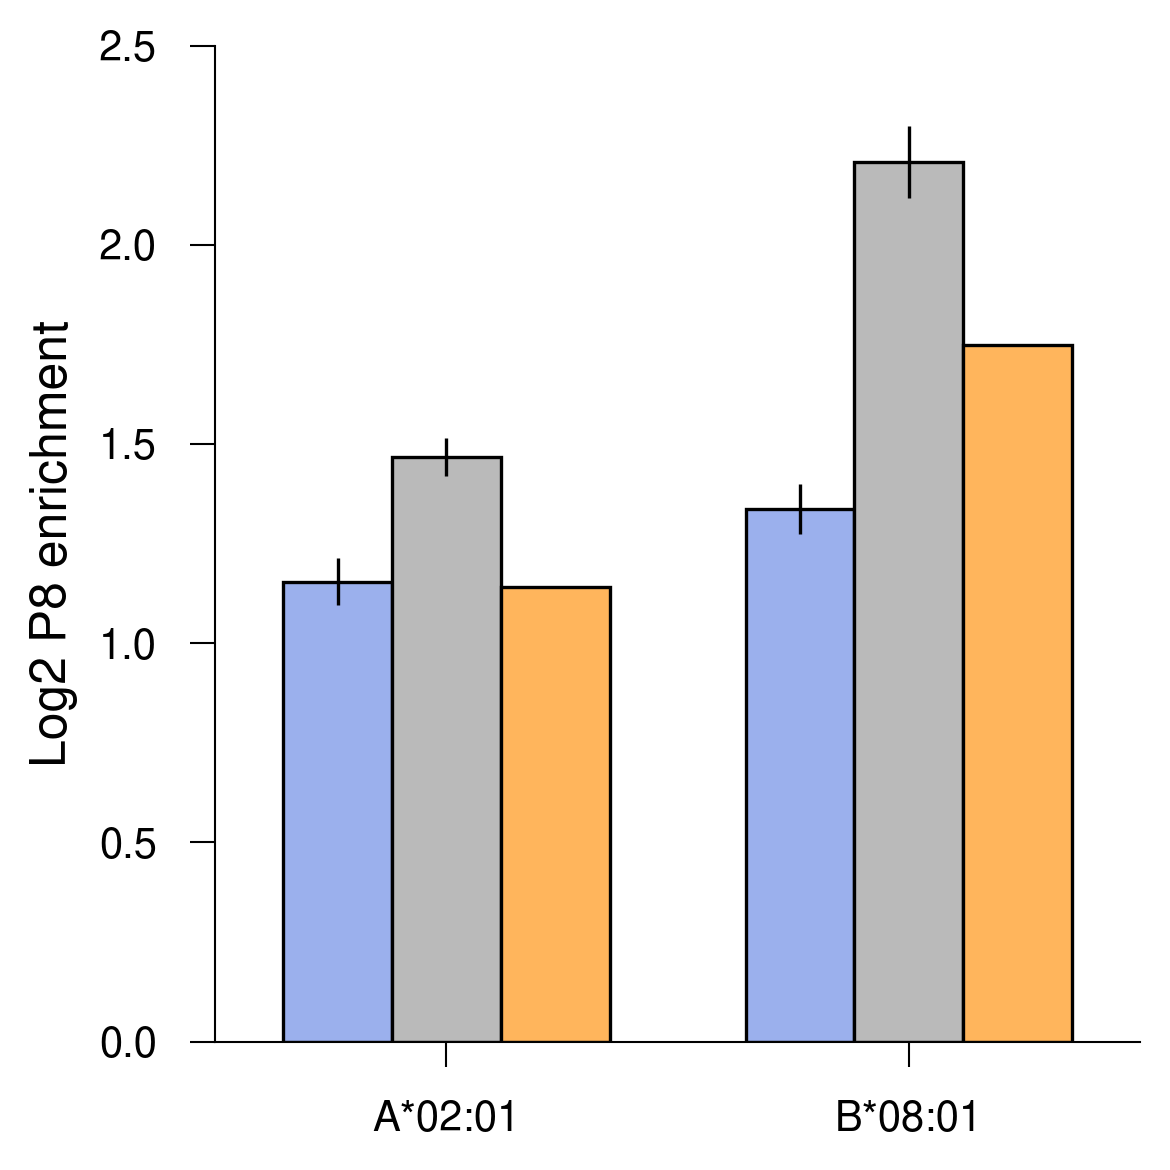

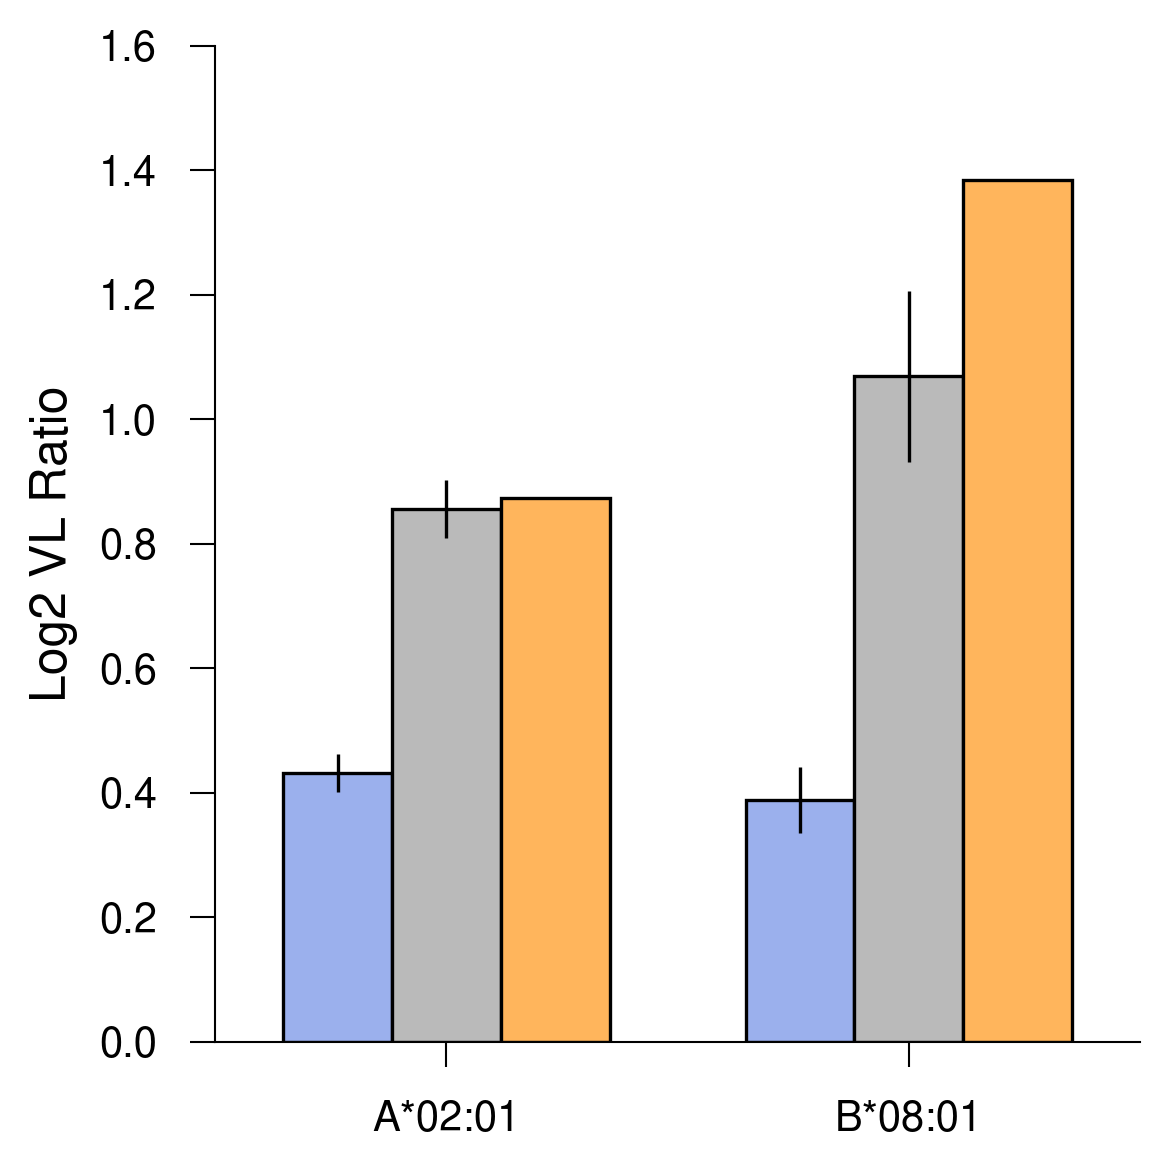

In [ ]:
# p8 enrichment barplot
model_groups = {
    'PepCL': ["episcan_r9rt_pepcl_a0201", "episcan_r9rt_pepcl_b0801"],
    'FT': ["episcan_r9rt_ft_a0201", "episcan_r9rt_ft_b0801"],
    'EpiScan_LO': ["episcan_r9rt_log_odds_a0201", "episcan_r9rt_log_odds_b0801"],
}

x_ticks = ["A*02:01", "B*08:01"]

colors = {
    'PepCL': "#9bb0ed",
    'FT': "#bababa",
    "EpiScan_LO": "#ffb55c"
}

plot_params = {
    'title': '',
    'title_fontsize': 16,
    'title_bold': False,
    'xlabel': '',
    'ylabel': '',
    'xlabel_fontsize': 12,
    'ylabel_fontsize': 12,
    'figsize': (4, 4),
    'dpi': 300,
    'legend_fontsize': 12,
    'legend_cols': 5,
    'legend_handle_size': 0.9,
    'marker_size': 3,
    'axis_linewidth': 0.5,
    'tick_length': 6.0,
    'xlabel_pad': 5.0,
    'ylabel_pad': 5.0,
    'xtick_labelsize': 10,
    'ytick_labelsize': 10
}

plotting_params=dict(
    model_col='model_name',
    model_groups=model_groups,
    x_ticks=x_ticks,
    colors=colors,
    plot_params=plot_params,
    grid_alpha=0.0,
    default_font='Nimbus Sans',
    bar_width=0.8,
    group_spacing=1,
    bar_spacing=0.0,
    bar_outline_color='black',
    bar_outline_width=0.8,
    hline_y=None,
    hline_label=None,
    hline_color='gray',
    hline_width=1.0,
    hline_style=':',
    hline_text=None,
    hline_text_position='above',
    hline_text_color=None,
    hline_text_fontsize=12,
    hline_text_offset=0.005,
    hline_text_x_offset=-0.035,
    hline_in_legend=True,
    legend_mode=None,
    mode='bar',
    box_flier_size=2,

)

plot_params["ylabel"]="Log2 P8 enrichment"
plotting_params['plot_params']=plot_params
plotting_params["score_col"]='p8_enrich'
plotting_params["ylim"]=(0.0, 2.5)
_=plot_model_performance_bars_or_box_v3(
    df=chp_l2fc_p8_enrich_a0201_b0801,
    interval_df=chp_l2fc_p8_enrich_a0201_b0801_ci,
    # save_path=f"{central_figure_dir}/fig6_b_episcan_r9rt_models_w_log_oods_a0201_b0801_log2_P8_enrichment_grouped_barplot_across_seeds",
    **plotting_params,
)

plot_params["ylabel"]="Log2 VL Ratio"
plotting_params['plot_params']=plot_params
plotting_params["ylim"]=(0.0, 1.6)
plotting_params["score_col"]='vl_shift'
_=plot_model_performance_bars_or_box_v3(
    df=epi_chp_vl_shift_log2_a0201_b0801,
    interval_df=epi_chp_vl_shift_log2_a0201_b0801_ci,
    # save_path=f"{central_figure_dir}/fig6_b_episcan_r9rt_w_logodds_a0201_b0801_log2_V9L9_tradeoff_alt_method_grouped_barplot_across_seeds",
    **plotting_params,
)

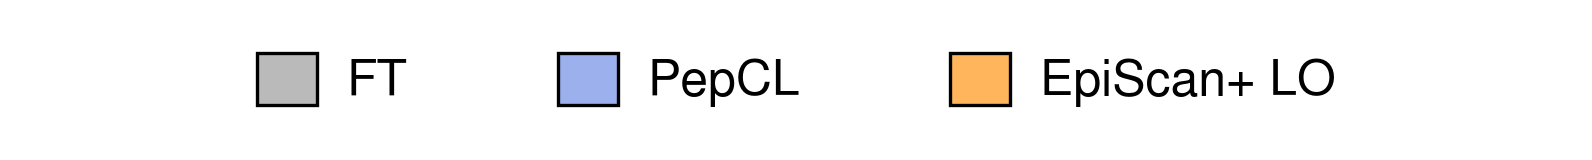

In [ ]:
# legend resized and formatted in illustrator
plot_horizontal_legend(
    legend_dict={
        'FT': '#bababa',
        'PepCL': '#9bb0ed',
        'EpiScan+ LO':'#ffb55c',
    },
    swatch_size=12,
    text_size=12,
    item_spacing=30,
    swatch_text_gap=6,
    swatch_outline_color='black',
    swatch_outline_width=0.8,
    figsize=None,
    dpi=300,
    default_font='Nimbus Sans',
    # save_path=f"{central_figure_dir}/fig6_b_legend",

)

In [ ]:
"""
Save dataframes associated with figures.
"""
save_dfs=False
# save_dfs=True

if save_dfs:
    chp_l2fc_p8_enrich_a0201_b0801.to_csv(f"{associated_data_dir}/chp_l2fc_p8_enrich_a0201_b0801.csv")
    epi_chp_vl_shift_log2_a0201_b0801.to_csv(f"{associated_data_dir}/epi_chp_vl_shift_log2_a0201_b0801.csv")
    chp_l2fc_p8_enrich_a0201_b0801_ci.to_csv(f"{associated_data_dir}/chp_l2fc_p8_enrich_a0201_b0801_ci.csv")
    epi_chp_vl_shift_log2_a0201_b0801_ci.to_csv(f"{associated_data_dir}/epi_chp_vl_shift_log2_a0201_b0801_ci.csv")

### Fig. 6d: YD ΔEntropy and JSD between FT and PepCL

In [ ]:
# load sp data for holec
swissprot_proteome_background_for_holec_df_processed=pd.read_csv(f"{DATA_DIR}/swissprot_proteome_background_for_holec_df_processed_yd_opt.csv", index_col=0)

# yd train set
holec_datasets_dir = DATA_DIR / "Training_Datasets" / "Processed" / "Holec_et_al_2025"
holec_train_set = pd.read_csv(f"{holec_datasets_dir}/holec_train_set.csv", index_col=0)

# ms train set
datasets_dir = DATA_DIR / "Training_Datasets" / "Processed" / "MS_Train_Test_Sets"
ms_train_data=pd.read_csv(f"{datasets_dir}/ms_train_data.csv", index_col=0)

# process and filter holec set
holec_train_set=full_process_data(holec_train_set, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
holec_train_set=create_seq_allele_column(holec_train_set)

holec_train_set["peptide"]=holec_train_set.seq.str.replace("$", "")
holec_train_set["seq_len"]=holec_train_set.peptide.apply(len)
holec_train_set_pos=holec_train_set.query("label == 1").copy()

# process and filter ms set
ms_train_data=full_process_data(ms_train_data, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
ms_train_data=create_seq_allele_column(ms_train_data)

ms_train_data["peptide"]=ms_train_data.seq.str.replace("$", "")
ms_train_data["seq_len"]=ms_train_data.peptide.apply(len)
ms_train_data_matched_allele_length_pos_9mers=ms_train_data[ms_train_data.allele.isin(holec_train_set.allele.unique().tolist())].query("seq_len == 9 and label == 1").copy()

# reset indices
swissprot_proteome_background_for_holec_df_processed.reset_index(inplace=True, drop=True)
holec_train_set_pos.reset_index(inplace=True, drop=True)
ms_train_data_matched_allele_length_pos_9mers.reset_index(inplace=True, drop=True)

In [ ]:
%%time
# entropy per position
score_cols=['mhcprime_abt', 'holec_pepcl_r_dr_steps_300_lr_2eN4_seed_1', 'holec_ft_steps_300_lr_2eN4_seed_3', 'holec_pepcl_r_dr_steps_300_lr_2eN4_seed_0', 'holec_ft_steps_300_lr_2eN4_seed_2', 'holec_ft_steps_300_lr_2eN4_seed_0', 'holec_pepcl_r_dr_steps_300_lr_2eN4_seed_3', 'holec_pepcl_r_dr_steps_300_lr_2eN4_seed_2', 'holec_pepcl_r_dr_steps_300_lr_2eN4_seed_4', 'holec_ft_steps_300_lr_2eN4_seed_4', 'holec_ft_steps_300_lr_2eN4_seed_1', 'holec_pepcl_r_dr_steps_300_lr_2eN4_seed_5', 'holec_ft_steps_300_lr_2eN4_seed_5', 'holec_pepcl_r_dr_steps_300_lr_2eN4_seed_6', 'holec_ft_steps_300_lr_2eN4_seed_6', 'holec_pepcl_r_dr_steps_300_lr_2eN4_seed_7', 'holec_ft_steps_300_lr_2eN4_seed_7', 'holec_pepcl_r_dr_steps_300_lr_2eN4_seed_8', 'holec_ft_steps_300_lr_2eN4_seed_8']

entropy_dict = compute_topk_position_entropy_by_allele(
    df=swissprot_proteome_background_for_holec_df_processed,
    score_cols=score_cols,
    allele_col="allele",
    seq_col="peptide",
    top_k=2000,
    log_base=2.0,
    pseudocount=0.0,
    device="cuda",
    show_progress=True,
)

# get delta
# entropy_dict["ft_pepcl_delta"]=entropy_dict["holec_ft"]-entropy_dict["holec_pepcl"]

entropy_delta=summarize_paired_seed_metric_delta(
    entropy_dict,
    ft_prefix="holec_ft_steps_300_lr_2eN4",
    pepcl_prefix="holec_pepcl_r_dr_steps_300_lr_2eN4",
)

Alleles: 100%|██████████| 16/16 [00:05<00:00,  2.92it/s]

CPU times: user 4.49 s, sys: 2.65 s, total: 7.14 s
Wall time: 7.15 s


In [ ]:
%%time
# positional jsd relative to another model
model_score_cols=[c for c in score_cols if c!="mhcprime_abt"]

positional_jsd_dict_relative_to_base=compute_topk_position_jsd_by_allele(
    df=swissprot_proteome_background_for_holec_df_processed,
    ref_score_col="mhcprime_abt",
    score_cols=model_score_cols,
    allele_col="allele",
    seq_col="peptide",
    top_k=2000,
    log_base=2.0,
    pseudocount=0.0,
    device="cuda",
    show_progress=True,
)

# get delta
jsd_delta=summarize_paired_seed_metric_delta(
    positional_jsd_dict_relative_to_base,
    ft_prefix="holec_ft_steps_300_lr_2eN4",
    pepcl_prefix="holec_pepcl_r_dr_steps_300_lr_2eN4",
)

Alleles: 100%|██████████| 16/16 [00:01<00:00, 10.37it/s]

CPU times: user 2.37 s, sys: 129 ms, total: 2.49 s
Wall time: 2.46 s


{'Positions': [1, 2, 3, 4, 5, 6, 7, 8, 9]}


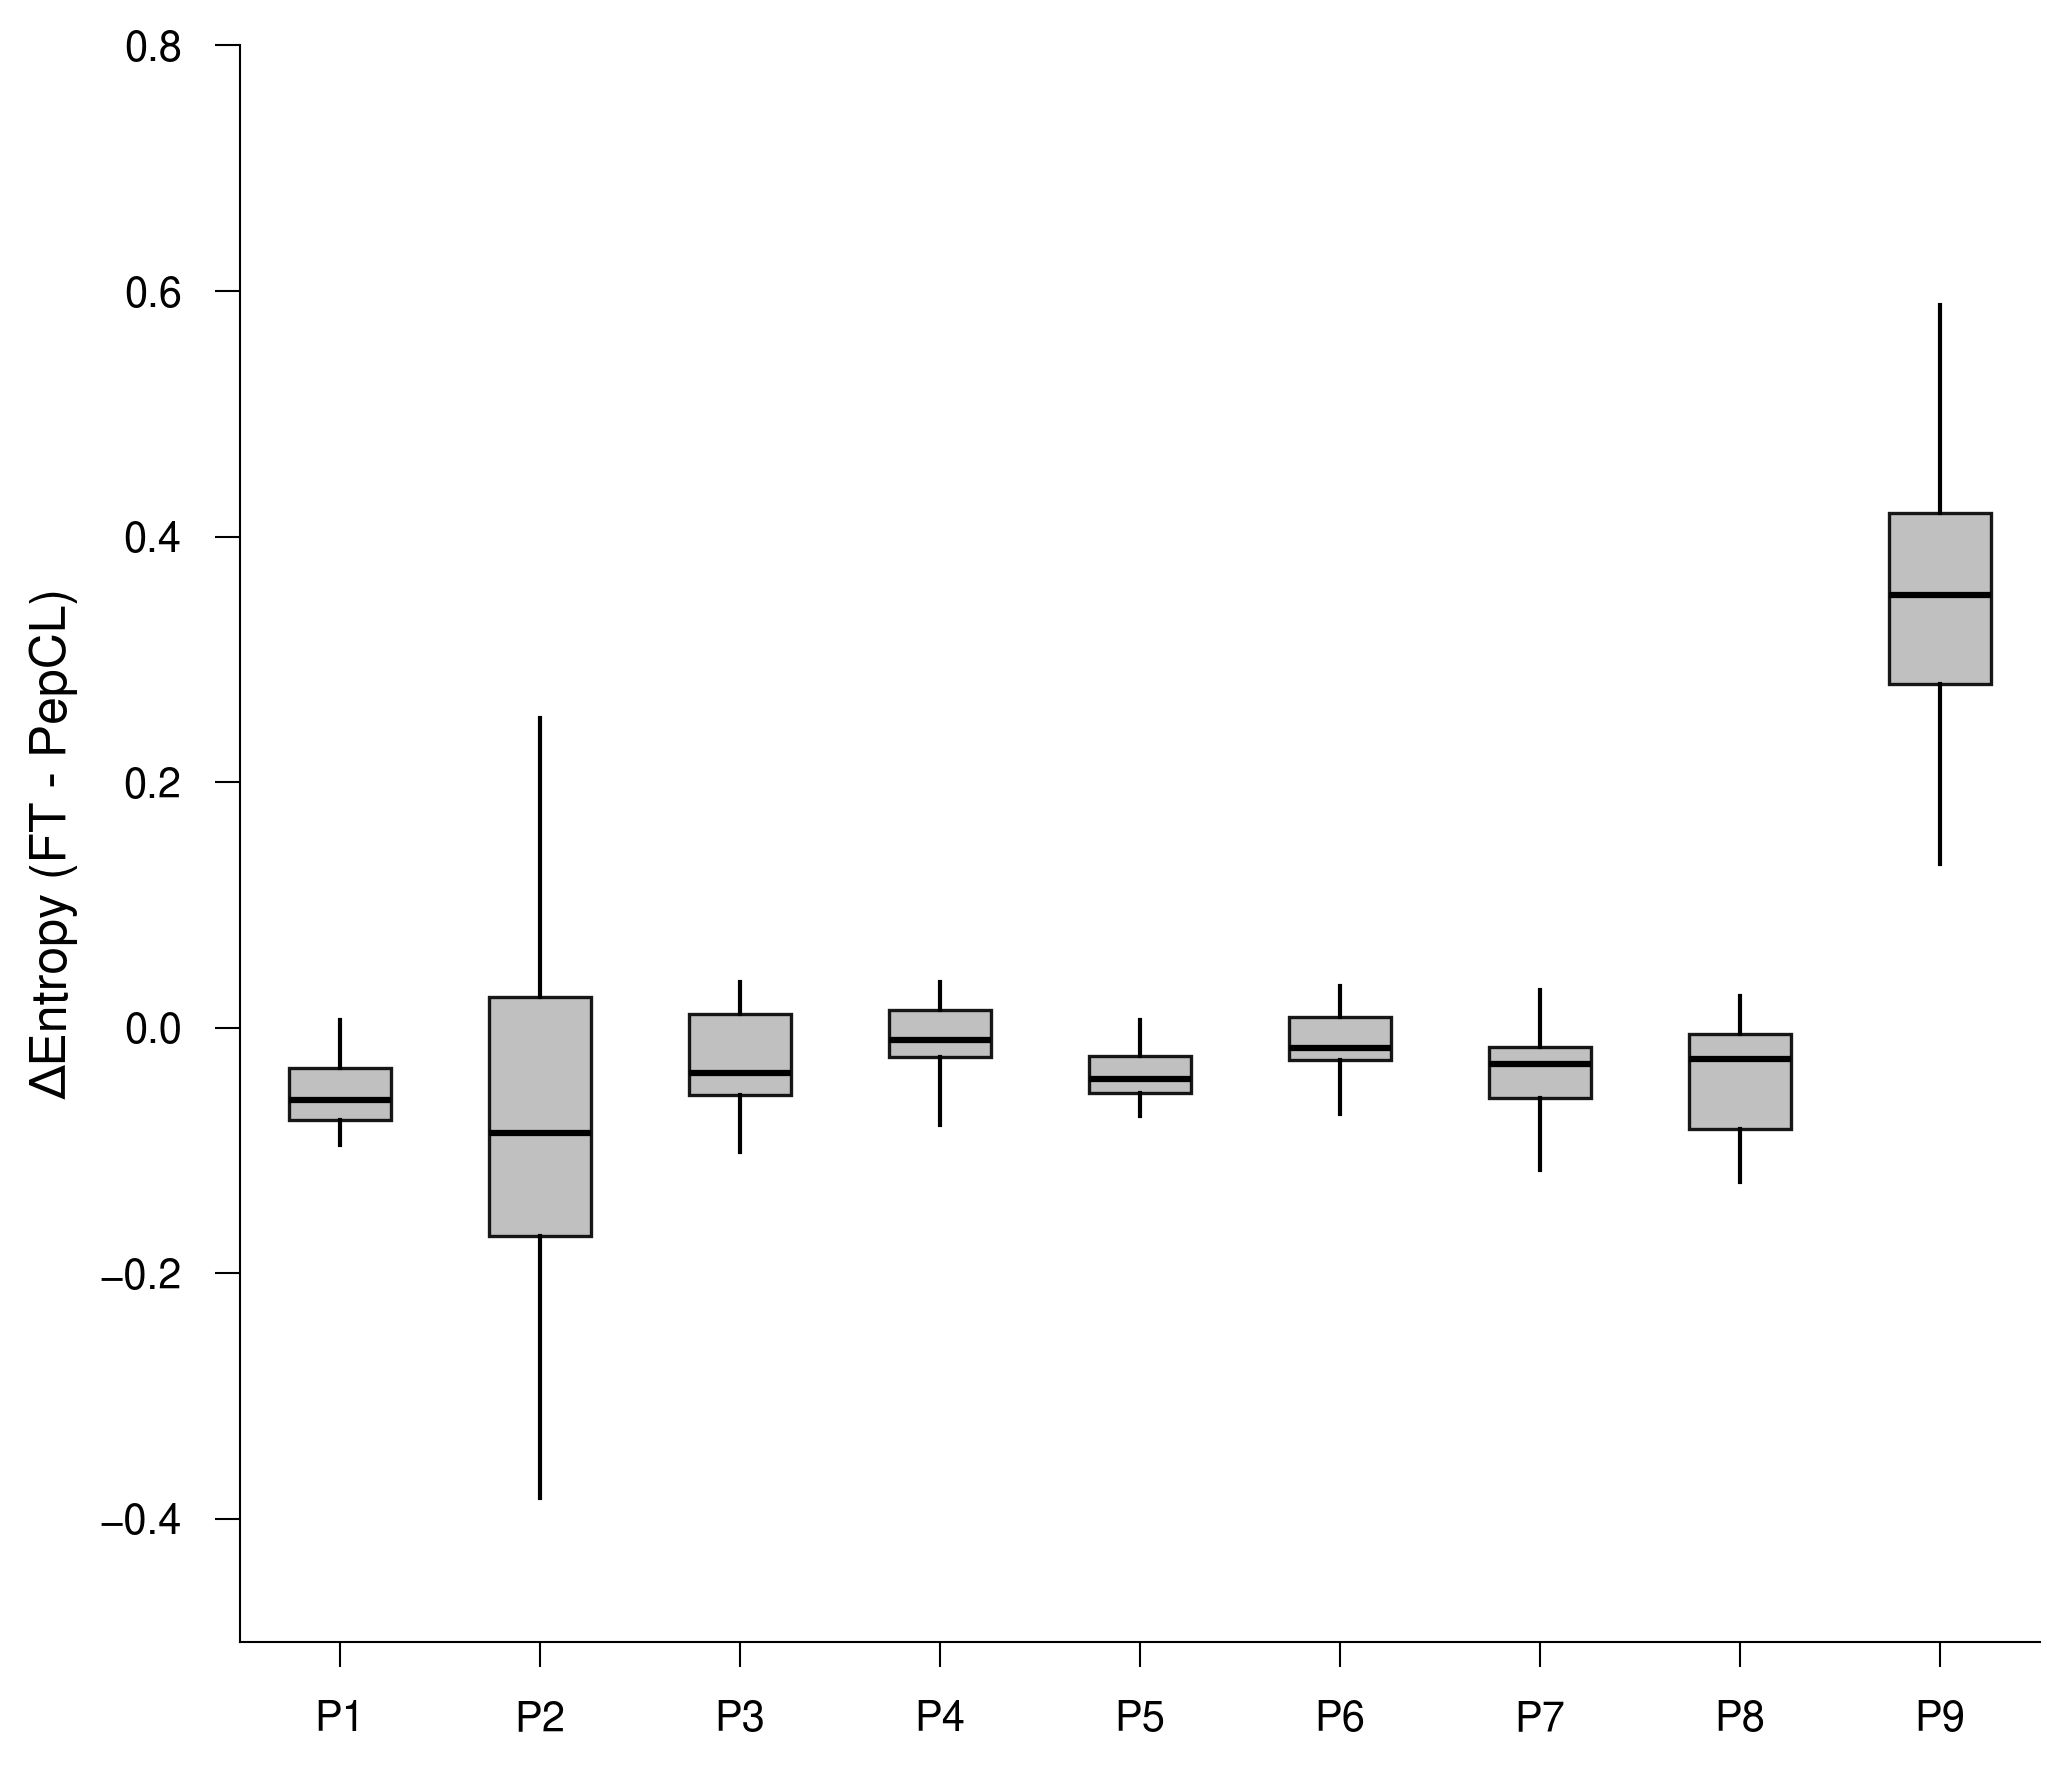

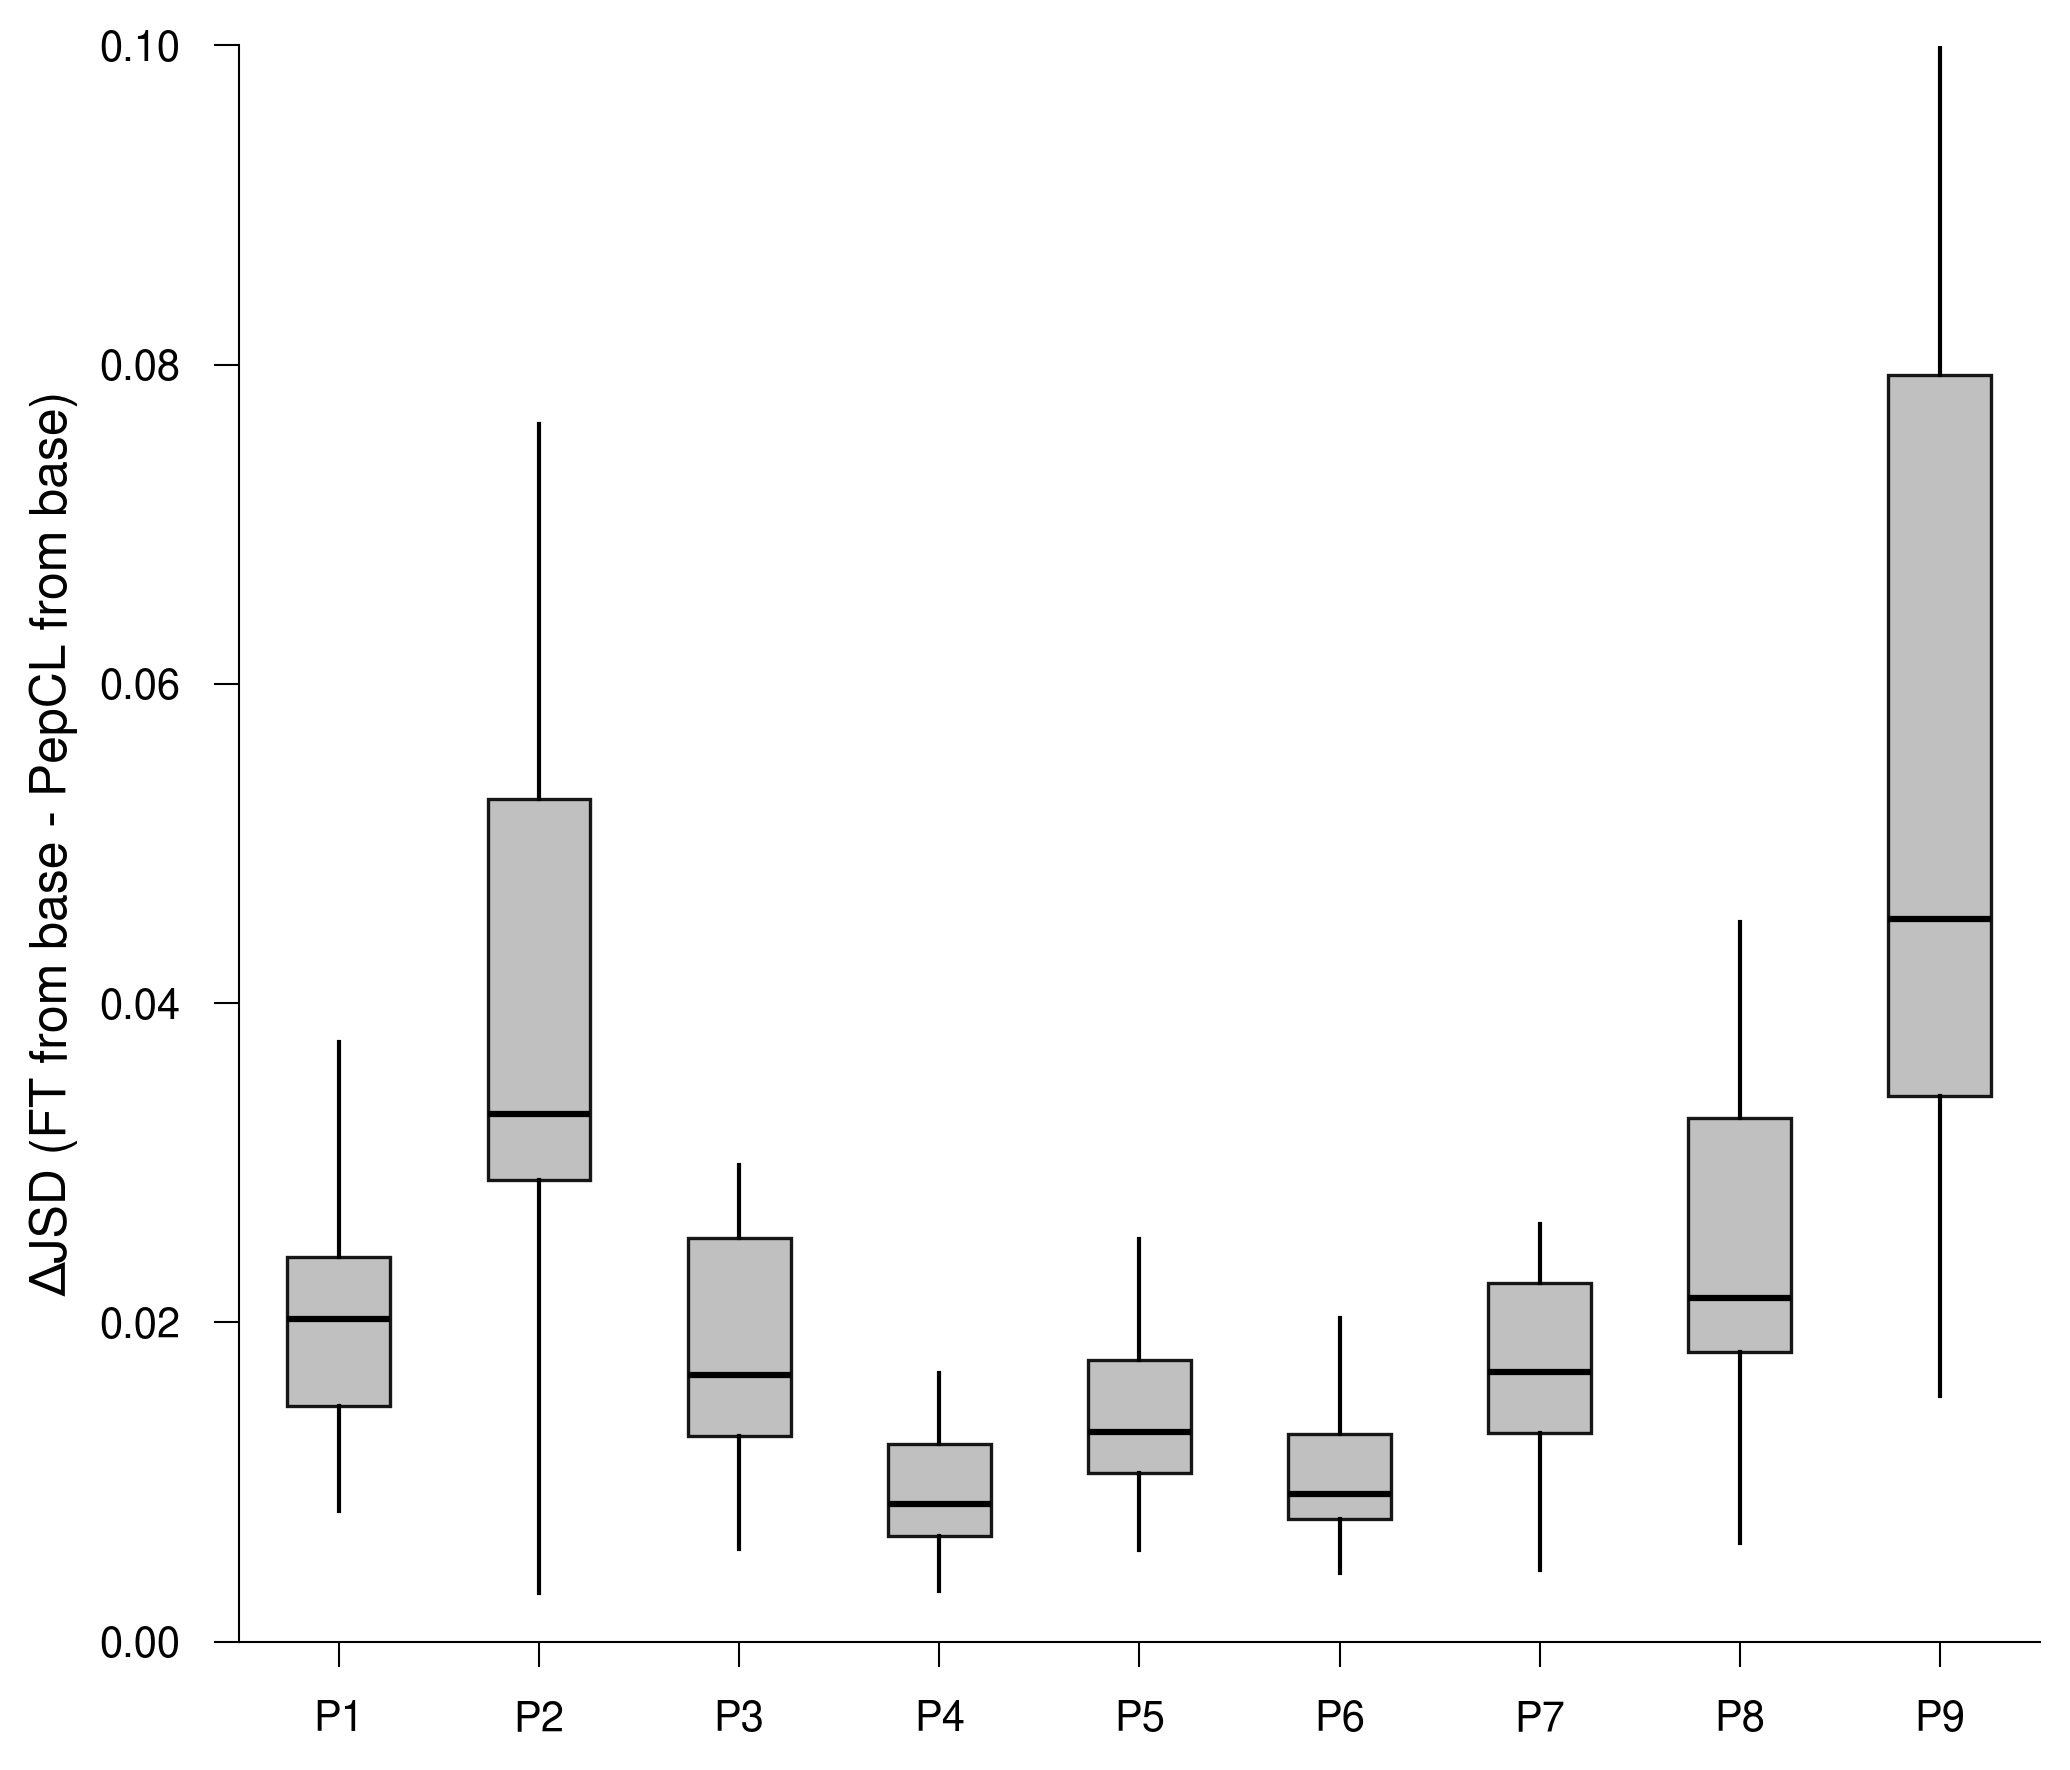

In [ ]:
# delta entropy boxplots
score_cols=['mhcprime', 'holec_ft', 'holec_pepcl']
model_groups = {
    'Positions': list(range(1, 10)),
}
x_ticks = ["P"+str(c) for c in list(range(1, 10))]  # just one group/tick
print(model_groups)

colors = {
    'Positions': '#bababa',
}

plot_params = {
    'title': '',
    'title_fontsize': 16,
    'title_bold': False,
    'xlabel': '',
    'ylabel': '',
    'xlabel_fontsize': 12,
    'ylabel_fontsize': 12,
    'figsize': (7, 6),
    'dpi': 300,
    'legend_fontsize': 12,
    'legend_cols': 5,
    'legend_handle_size': 0.9,
    'marker_size': 3,
    'axis_linewidth': 0.5,
    'tick_length': 6.0,
    'xlabel_pad': 5.0,
    'ylabel_pad': 5.0,
    'xtick_labelsize': 10,
    'ytick_labelsize': 10

}

plotting_params=dict(
    model_col='model_name',
    score_col='metric',
    model_groups=model_groups,
    x_ticks=x_ticks,
    colors=colors,
    plot_params=plot_params,
    ylim=None,
    grid_alpha=0,
    default_font='Nimbus Sans',
    bar_width=2.0,
    group_spacing=1.5,
    bar_spacing=0.0,
    bar_outline_color='black',
    bar_outline_width=0.8,
    hline_y=None,
    hline_label=None,
    hline_color='gray',
    hline_width=1.0,
    hline_style=':',
    hline_text=None,
    hline_text_position='above',
    hline_text_color=None,
    hline_text_fontsize=12,
    hline_text_offset=0.005,
    hline_text_x_offset=-0.035,
    hline_in_legend=True,
    legend_mode=None,
    mode='box',
    box_flier_size=0,
    xtick_rotation=0,
    x_margin=None,

)

plot_params["ylabel"]='ΔEntropy (FT - PepCL)'
plotting_params['plot_params']=plot_params
plotting_params['ylim']=(-0.5, 0.8)
_=plot_model_performance_bars_or_box_v2(
    df=entropy_delta["mean"],
    # save_path=f"{central_figure_dir}/fig6_d_holec_ft_pepcl_entropy_delta_per_position_boxplot_across_seeds",
    **plotting_params,
)


plot_params["ylabel"]='ΔJSD (FT from base - PepCL from base)'
plotting_params['plot_params']=plot_params
plotting_params['ylim']=(0.0, 0.1)
_=plot_model_performance_bars_or_box_v2(
    # df=positional_jsd_dict_relative_to_base["ft_pepcl_delta"], 
    df=jsd_delta["mean"], 
    # save_path=f"{central_figure_dir}/fig6_d_holec_ft_pepcl_jsd_per_position_boxplot_across_seeds",
    **plotting_params,
)


In [ ]:
"""
Save dataframes associated with figures.
"""

save_dfs=False
# save_dfs=True

if save_dfs:
    entropy_delta["mean"].to_csv(f"{associated_data_dir}/ft_delta_entropy_delta_per_allele_position")
    jsd_delta["mean"].to_csv(f"{associated_data_dir}/positional_jsd_relative_to_base_ft_pepcl_delta_per_allele_position.csv")

### Fig. 6e: YD ΔEntropy and JSD between FT and PepCL at PΩ 

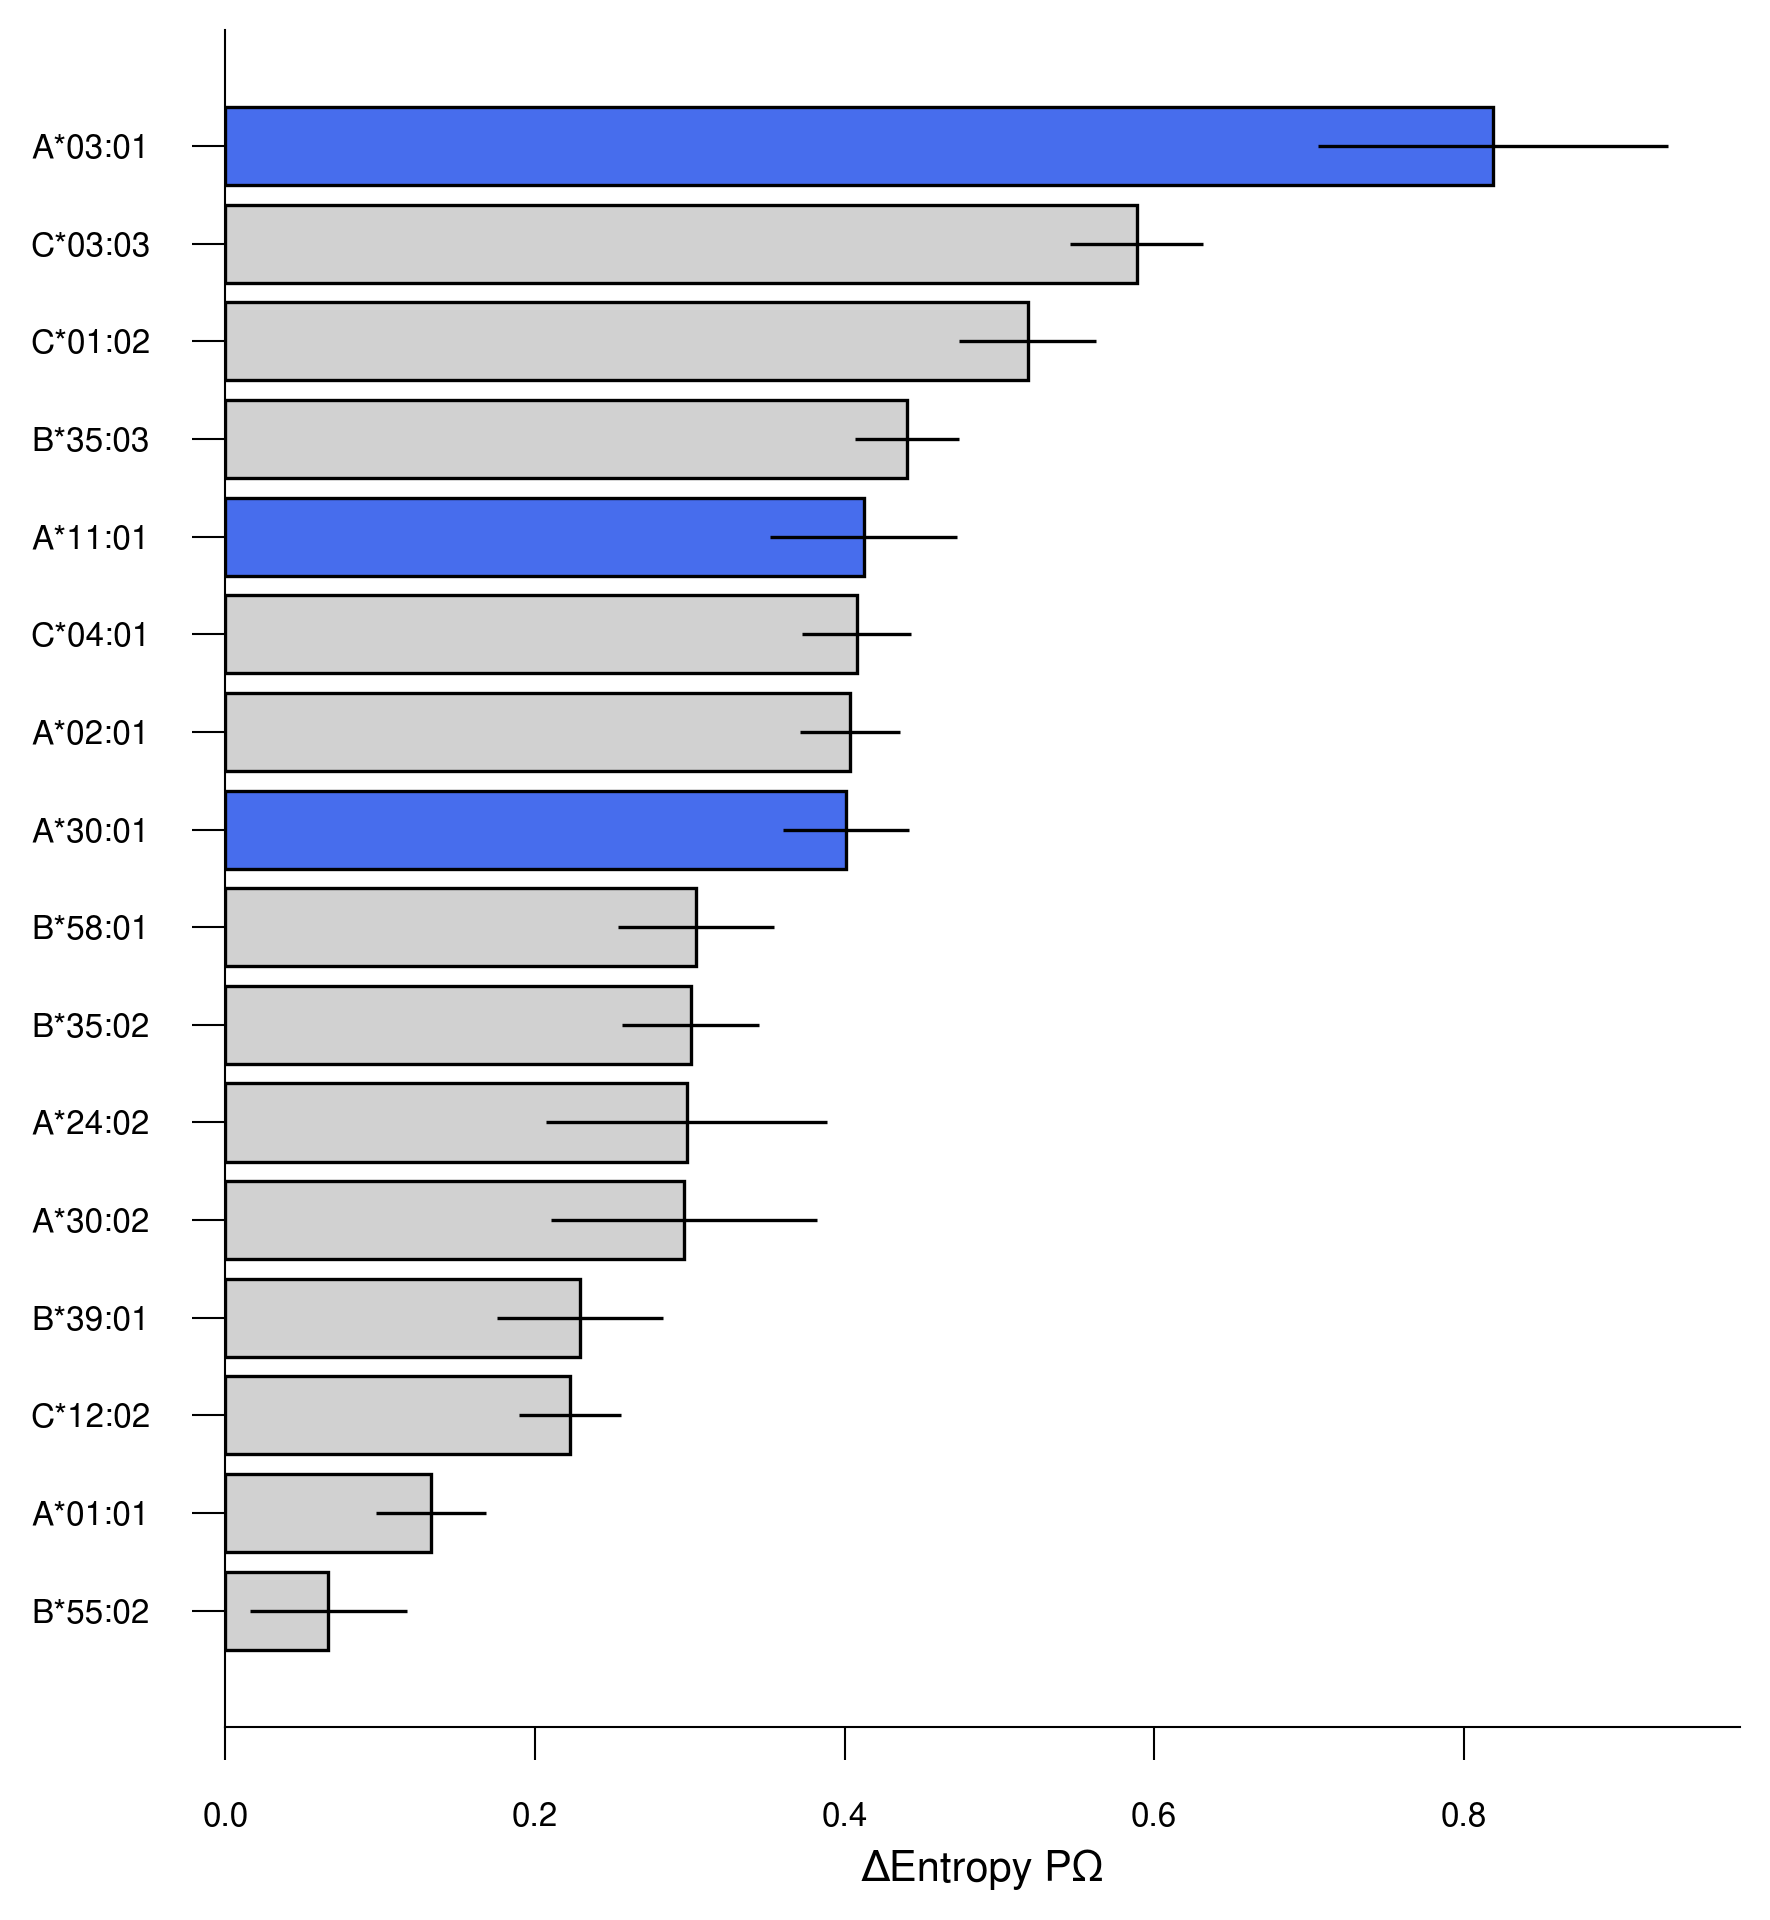

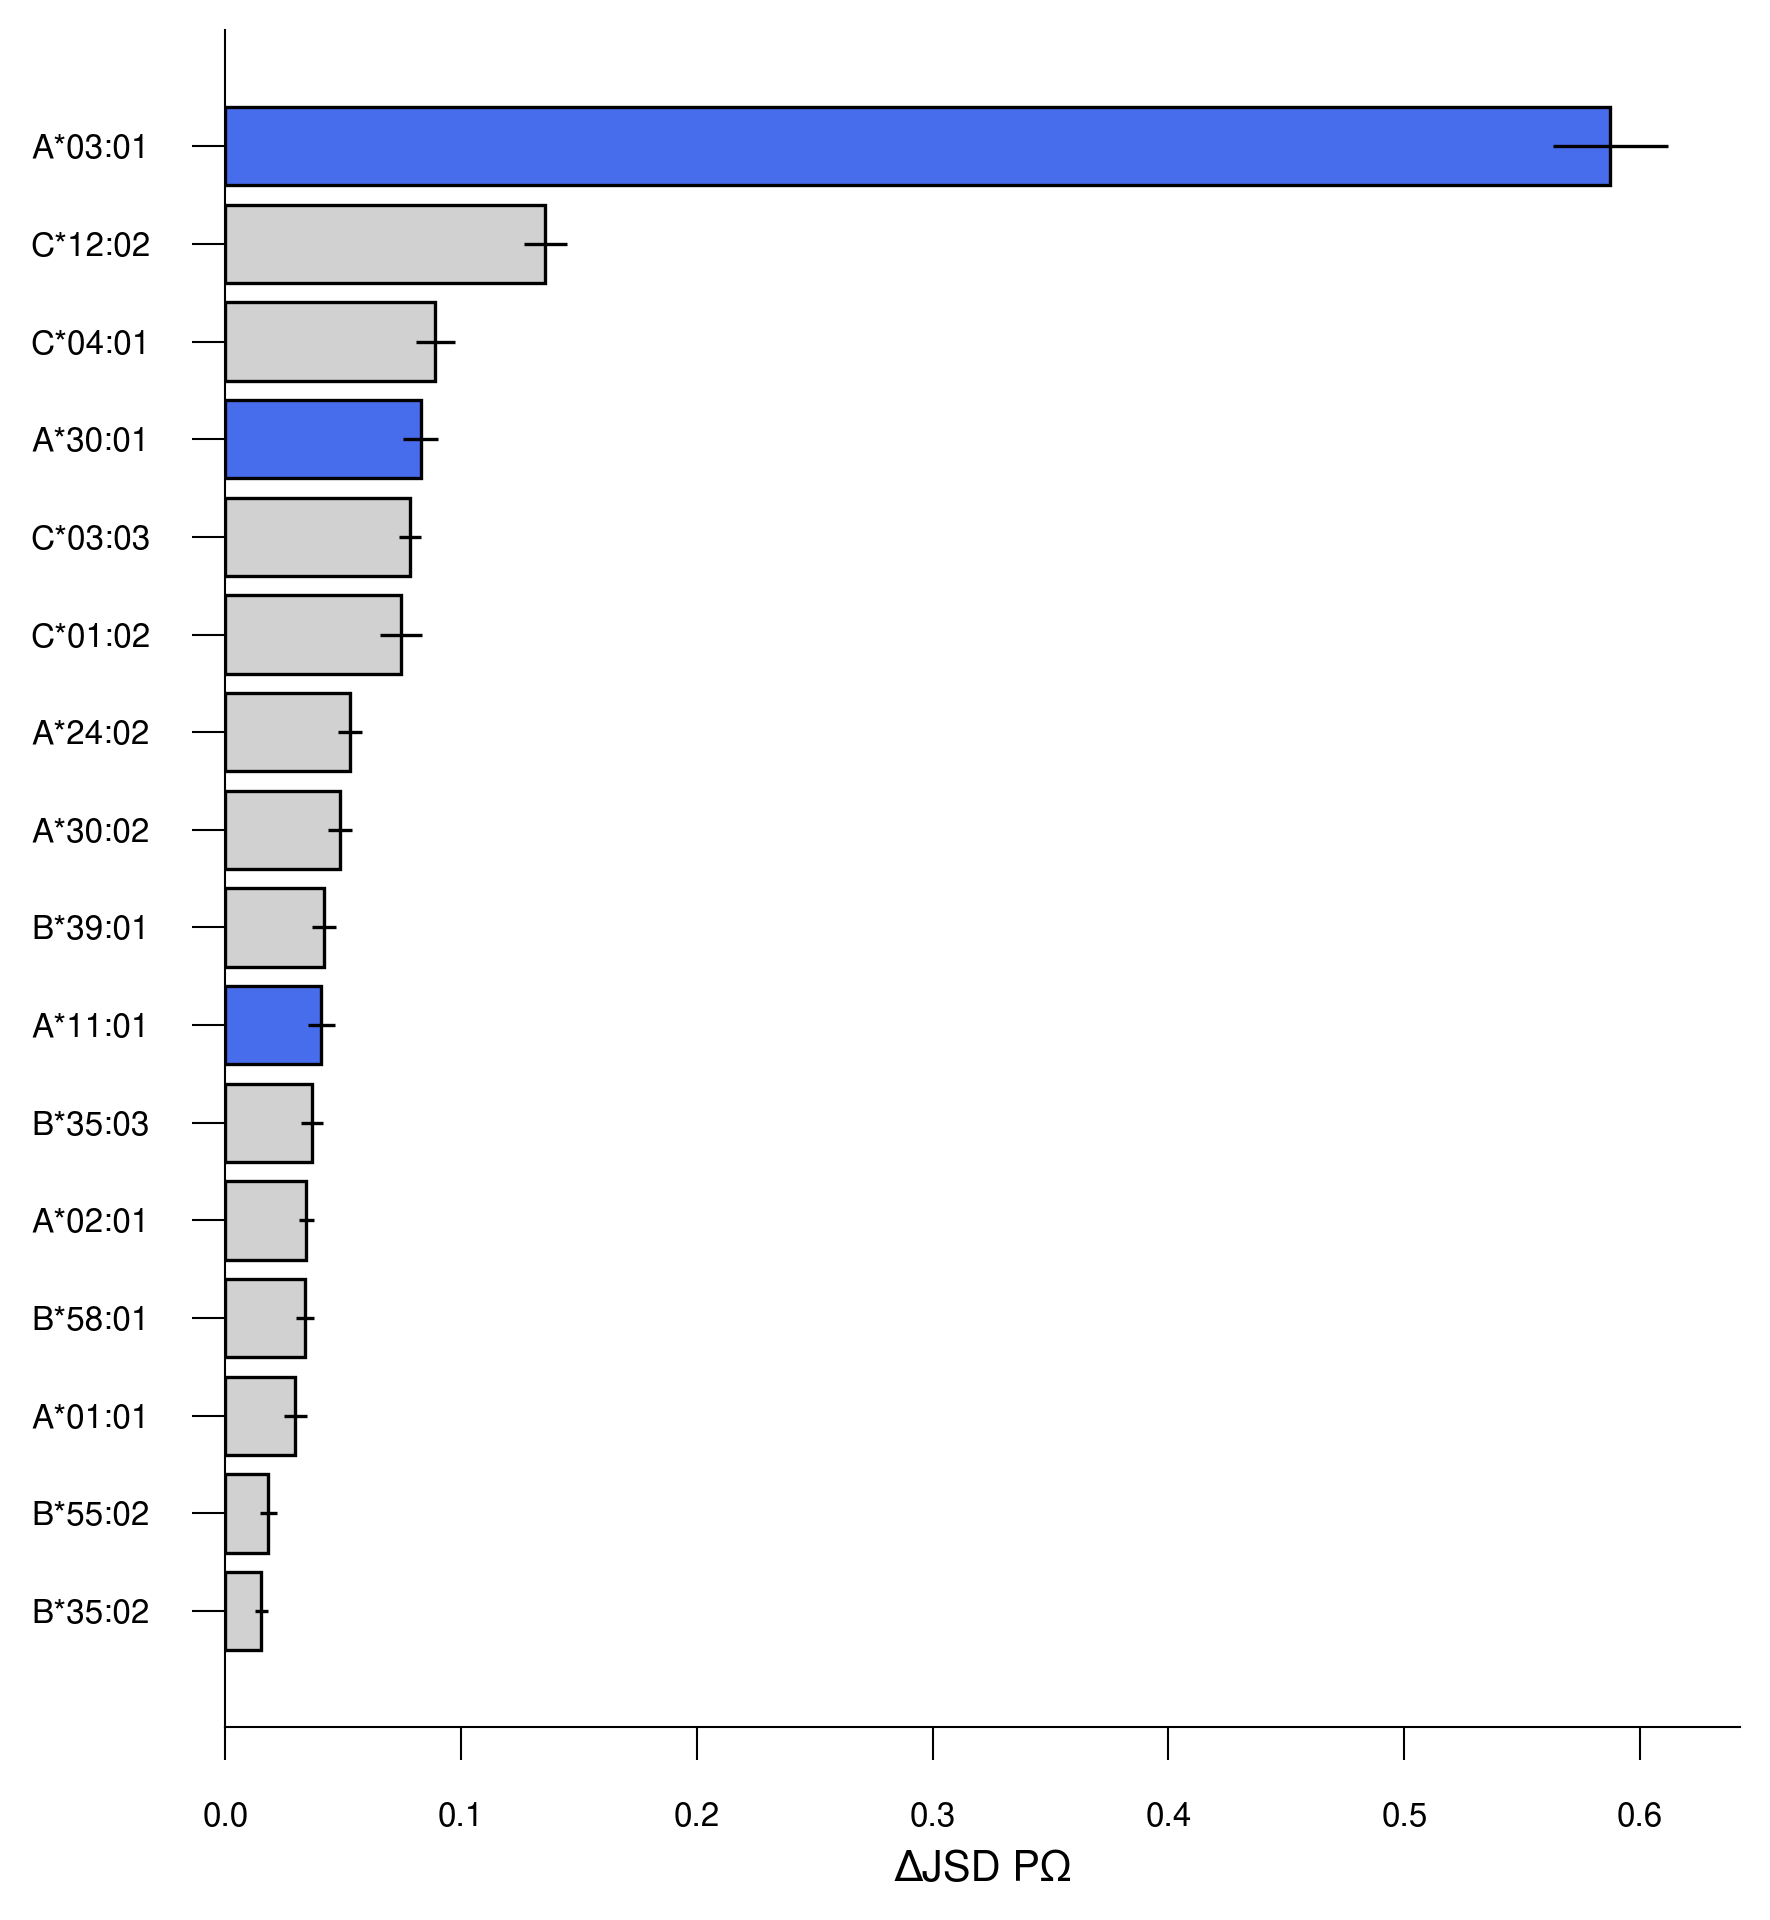

In [ ]:
# plot per allele barplots
highlight_colors=["#476DED", "#D1D1D1"]
col=9
figsize=(6, 6.5)

def format_allele_index(df):
    """Format allele index: A0201 -> A*02:01."""
    out=df.copy()
    out.index=[f"{a[0]}*{a[1:3]}:{a[3:5]}" if len(str(a))==5 else a for a in out.index.astype(str)]
    return out

entropy_mean=entropy_delta["mean"].sort_values(by=col,ascending=False)
entropy_mean_ci_low=entropy_delta["ci_low"]
entropy_mean_ci_high=entropy_delta["ci_high"]

jsd_mean=jsd_delta["mean"].sort_values(by=col,ascending=False)
jsd_mean_ci_low=jsd_delta["ci_low"]
jsd_mean_ci_high=jsd_delta["ci_high"]

entropy_mean=format_allele_index(entropy_mean)
entropy_mean_ci_low=format_allele_index(entropy_mean_ci_low)
entropy_mean_ci_high=format_allele_index(entropy_mean_ci_high)

jsd_mean=format_allele_index(jsd_mean)
jsd_mean_ci_low=format_allele_index(jsd_mean_ci_low)
jsd_mean_ci_high=format_allele_index(jsd_mean_ci_high)

plotting_params=dict(
    figsize=figsize,
    dpi=300,
    default_font='Nimbus Sans',
    color='steelblue',
    bar_width=0.8,
    bar_edgecolor='black',
    bar_edgewidth=0.8,
    alpha=1.0,
    # highlight_ticks=["A0301", "A1101", "A3001"],
    highlight_ticks=["A*03:01", "A*11:01", "A*30:01"], 
    highlight_colors=highlight_colors,
    horizontal=True,
    xlabel='',
    ylabel=None,
    xlabel_fontsize=10,
    ylabel_fontsize=10,
    xlabel_pad=4.0,
    ylabel_pad=4.0,
    title='',
    title_fontsize=12,
    title_bold=True,
    xtick_labelsize=8,
    ytick_labelsize=8,
    tick_length=8.0,
    tick_width=0.5,
    tick_direction='out',
    rotation=0,
    axis_linewidth=0.5,
    ylim=None,
    xlim=None,
    grid_alpha=0.0,
)

plotting_params["ylabel"]='ΔEntropy PΩ'
_=plot_bar_advanced_w_ci(
    entropy_mean,
    col,
    interval_low_df=entropy_mean_ci_low,
    interval_high_df=entropy_mean_ci_high,
    # save_path=f"{central_figure_dir}/fig6_e_holec_p9_entropy_delta_ft_v_pepcl_per_allele_barplot_across_seeds",
    **plotting_params,
)

plotting_params["ylabel"]='ΔJSD PΩ'
_=plot_bar_advanced_w_ci(
    jsd_mean,
    col,
    interval_low_df=jsd_mean_ci_low,
    interval_high_df=jsd_mean_ci_high,
    # save_path=f"{central_figure_dir}/fig6_e_holec_p9_jsd_ft_v_pepcl_per_allele_barplot_across_seeds",
    **plotting_params,
)

In [ ]:
"""
Save dataframes associated with figures.
"""

save_dfs=False
# save_dfs=True

if save_dfs:
    entropy_mean.to_csv(f"{associated_data_dir}/entropy_mean_fig6_e.csv")
    entropy_mean_ci_low.to_csv(f"{associated_data_dir}/entropy_mean_ci_low_fig6_e.csv")
    entropy_mean_ci_high.to_csv(f"{associated_data_dir}/entropy_mean_ci_high_fig6_e.csv")

    jsd_mean.to_csv(f"{associated_data_dir}/jsd_mean_fig6_e.csv")
    jsd_mean_ci_low.to_csv(f"{associated_data_dir}/jsd_mean_ci_low_fig6_e.csv")
    jsd_mean_ci_high.to_csv(f"{associated_data_dir}/jsd_mean_ci_high_fig6_e.csv")

### Fig. 6f: Sequence logo plots for A0301, A3001, and A1101

In [ ]:
# logo plots for target alleles
score_cols_temp=["holec_ft", "holec_pepcl"]
target_alleles=["A0301", "A3001", "A1101"]

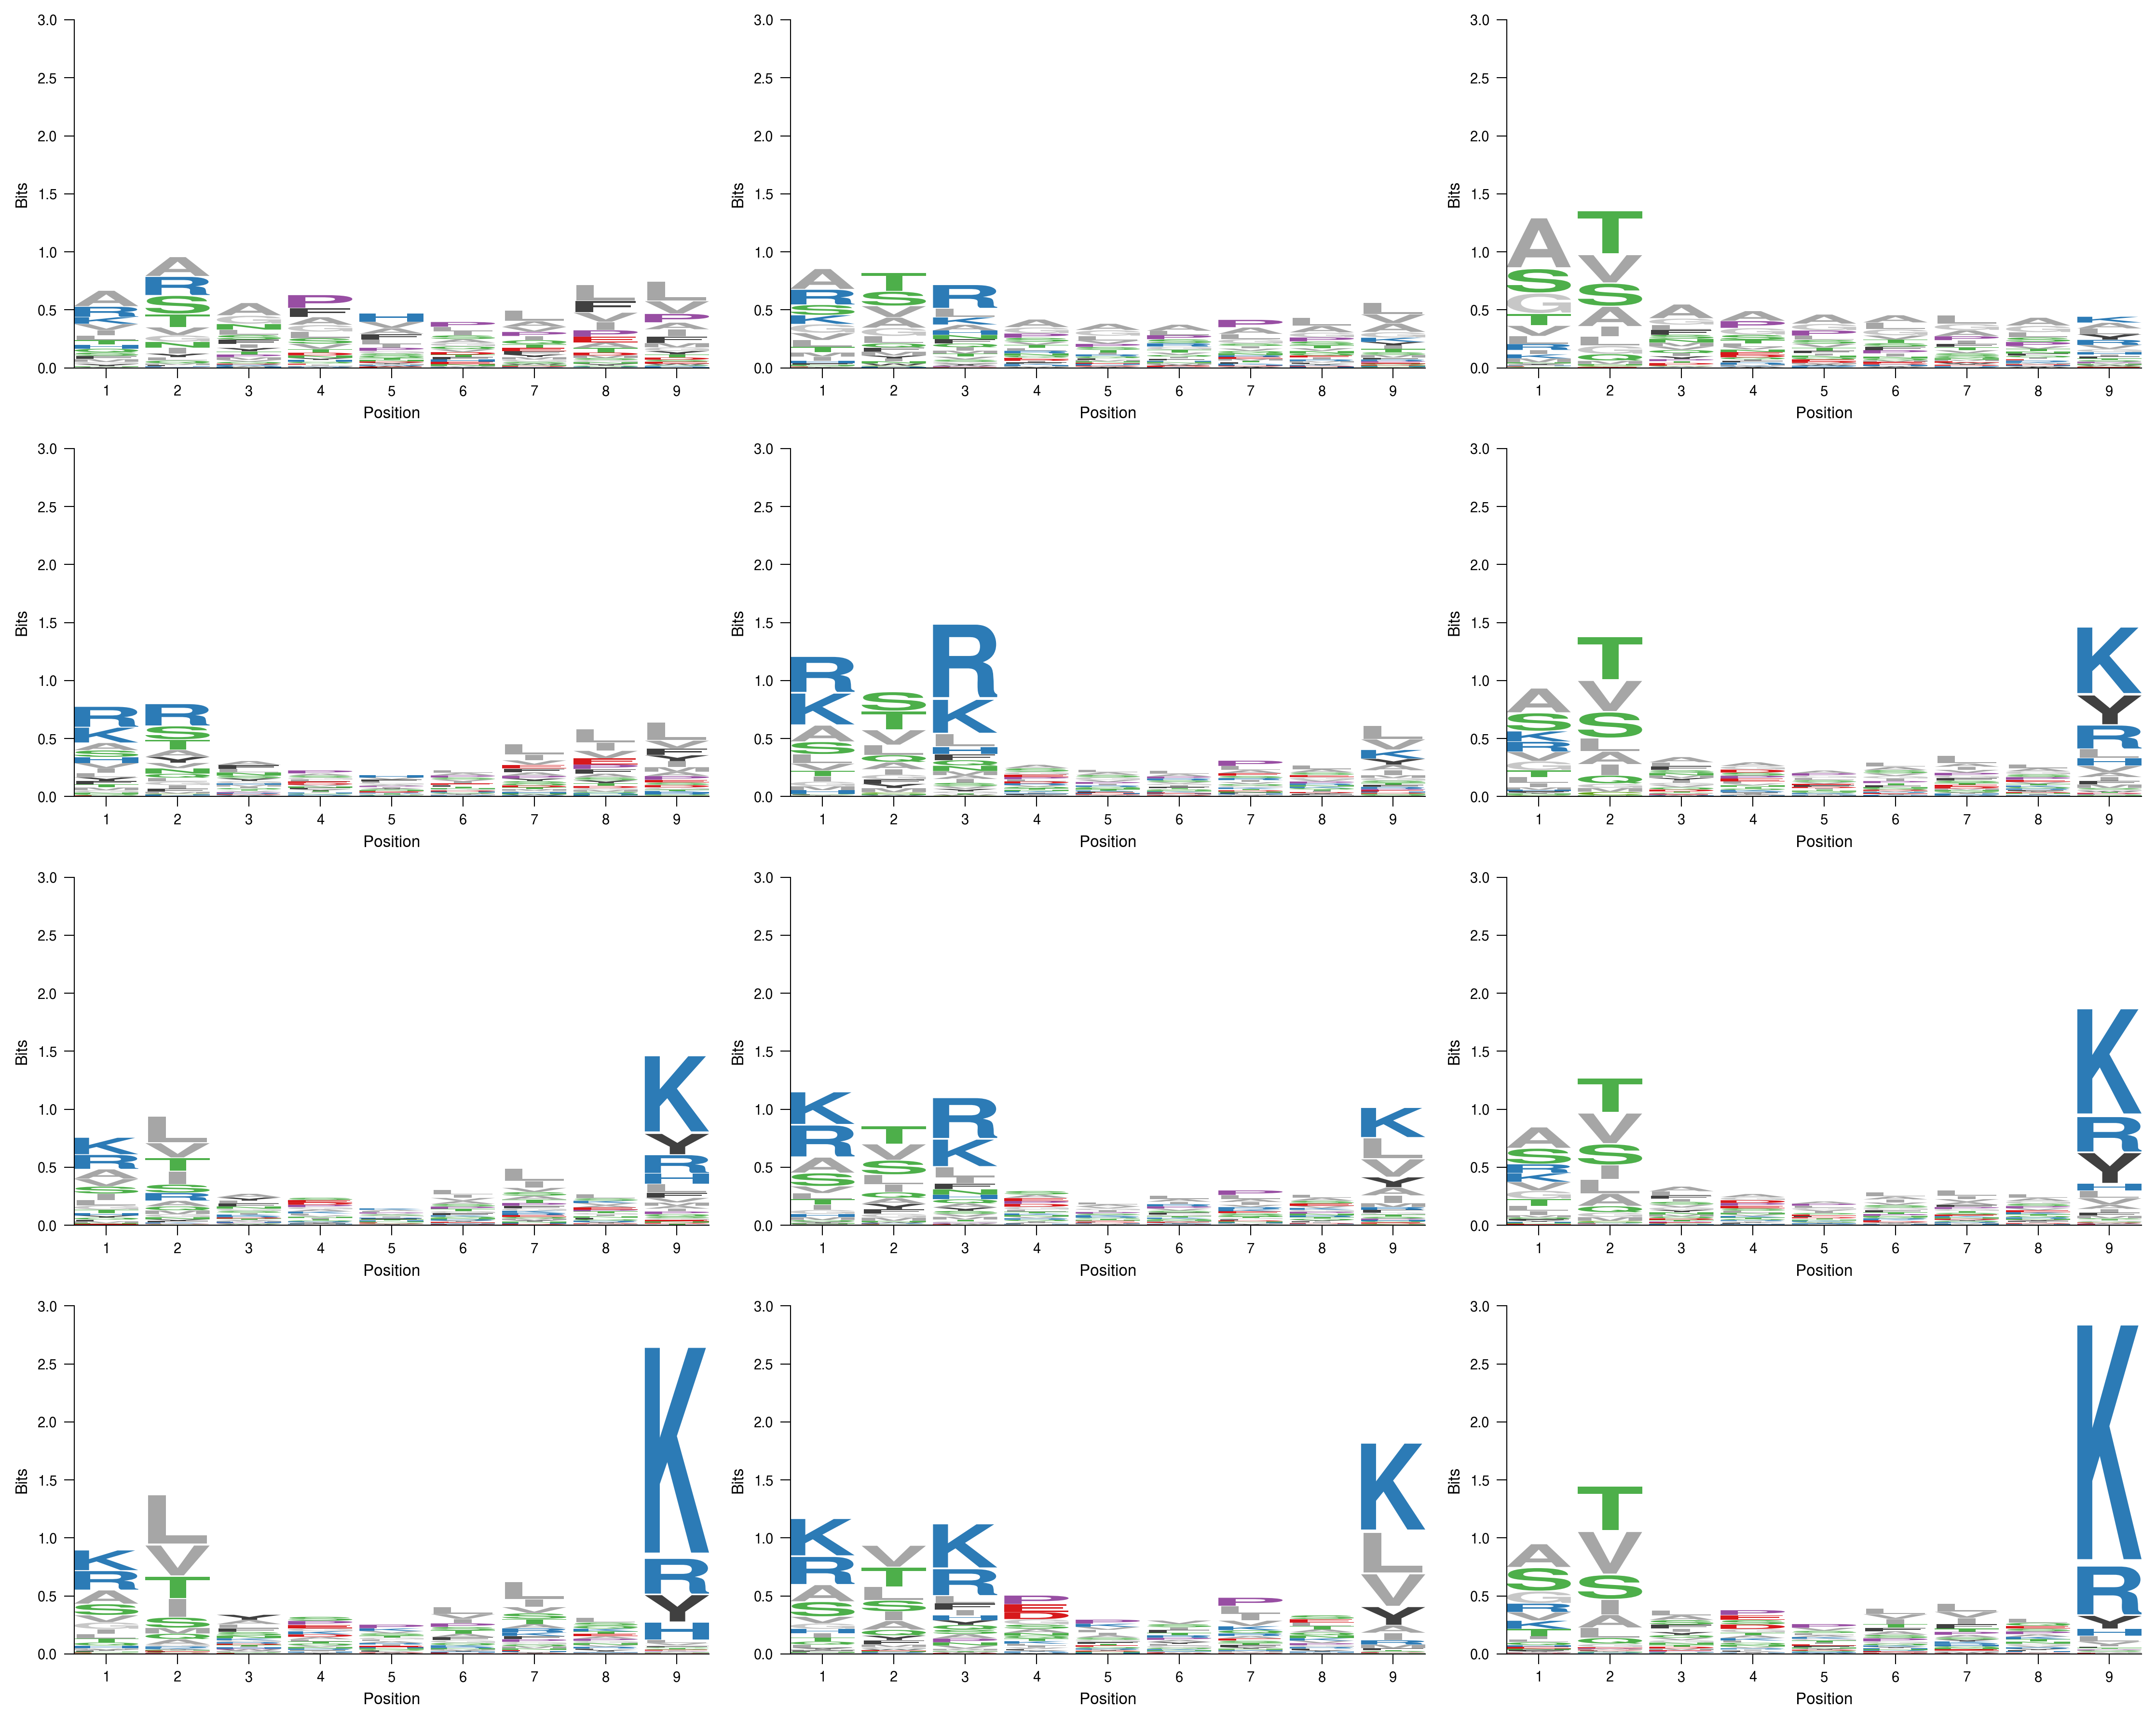

In [ ]:
score_cols=['mhcprime_abt', 'holec_pepcl_r_dr_steps_300_lr_2eN4_seed_1', 'holec_ft_steps_300_lr_2eN4_seed_3', 'holec_pepcl_r_dr_steps_300_lr_2eN4_seed_0', 'holec_ft_steps_300_lr_2eN4_seed_2', 'holec_ft_steps_300_lr_2eN4_seed_0', 'holec_pepcl_r_dr_steps_300_lr_2eN4_seed_3', 'holec_pepcl_r_dr_steps_300_lr_2eN4_seed_2', 'holec_pepcl_r_dr_steps_300_lr_2eN4_seed_4', 'holec_ft_steps_300_lr_2eN4_seed_4', 'holec_ft_steps_300_lr_2eN4_seed_1', 'holec_pepcl_r_dr_steps_300_lr_2eN4_seed_5', 'holec_ft_steps_300_lr_2eN4_seed_5', 'holec_pepcl_r_dr_steps_300_lr_2eN4_seed_6', 'holec_ft_steps_300_lr_2eN4_seed_6', 'holec_pepcl_r_dr_steps_300_lr_2eN4_seed_7', 'holec_ft_steps_300_lr_2eN4_seed_7', 'holec_pepcl_r_dr_steps_300_lr_2eN4_seed_8', 'holec_ft_steps_300_lr_2eN4_seed_8']

ft_score_cols=[
    c for c in score_cols
    if c.startswith("holec_ft_steps_300_lr_2eN4_seed_")
]

pepcl_score_cols=[
    c for c in score_cols
    if c.startswith("holec_pepcl_r_dr_steps_300_lr_2eN4_seed_")
]

target_alleles=["A0301","A3001","A1101"]
_=plot_pwm_logo_grid_seed_averaged(
    holec_train_df=holec_train_set_pos,
    background_df=swissprot_proteome_background_for_holec_df_processed,
    ms_train_df=ms_train_data_matched_allele_length_pos_9mers,
    ft_score_cols=ft_score_cols,
    pepcl_score_cols=pepcl_score_cols,
    alleles=target_alleles,
    allele_col="allele",
    peptide_col="peptide",
    top_n=2000,
    figsize_per_cell=(5, 3),
    dpi=300,
    default_font='Nimbus Sans',
    title="",
    title_fontsize=9,
    title_bold=False,
    show_n_in_title=False,
    ylabel='Bits',
    xlabel='Position',
    xlabel_fontsize=8,
    ylabel_fontsize=8,
    xlabel_pad=4.0,
    ylabel_pad=4.0,
    xtick_labelsize=7,
    ytick_labelsize=7,
    color_scheme=None,
    vpad=0.05,
    logo_width=0.9,
    highlight_cysteine=False,
    cysteine_color='#FF3D3D',
    non_cysteine_color='#D9D9D9',
    ylim=(0, 3.0),
    spine_width=0.5,
    remove_top_right_spines=True,
    tick_length=5.0,
    tick_width=0.5,
    tick_direction='out',
    square_aspect=False,
    # save_path=f"{central_figure_dir}/fig6_f_sequence_logo_plot_grid_holec_train_sp_top_2k_peptides_ft_pepcl_model_ms_train_A0301_A3001_A1101_s2l_colors_across_seeds",
)